# Estimation Theory & Regression Inference | Phase 2

**Mahdi Abazari Aghdam · Sharif University of Technology**

This executed notebook answers every question in the original Phase 2 assignment. Part A estimates an exponential mean lifetime; Part B derives and tests a simple temperature-hardness regression. The reported estimators use course formulas and base arithmetic. Library fits are isolated as verification. A single fixed NumPy generator (seed `403109076`) makes all Monte Carlo and bootstrap outputs reproducible.

| Part | Steps | Main deliverable |
|---|---|---|
| A: Reliability | A1–A8 | MoM, MLE, bias, consistency, efficiency, intervals, reliability |
| B: Process regression | B1–B8 | OLS, MLE equivalence, inference, diagnostics, prediction |


## 0 | Run the entire pipeline

This cell validates both supplied CSV files and regenerates the results JSON plus 14 high-resolution figures. All later cells show outputs from that single run.

In [1]:
from IPython.display import display, Image
import pandas as pd
from src.run_all import main, FIG
R = main()
A, B = R['part_a'], R['part_b']
print('Seed:', R['seed'], '| Figures:', len(list(FIG.glob('*.png'))))

Saved C:\Users\MEHR\Desktop\IT_PRJ_21776_GROUP_1\tmp\engineering-statistics-portfolio\phase2\reports\results.json and 14 figures
Seed: 403109076 | Figures: 14


# Part A | Exponential reliability estimation

Model: independent lifetimes $X_i \sim \mathrm{Exponential}(\theta)$ with mean and standard deviation $\theta>0$. This is an assumption to assess, not a fact established by the CSV.

### A1. Explore the failure-time sample

Report n, mean, median, sample SD, range, and CV = sample SD / mean. The exponential model has population CV = 1 because its mean and SD both equal θ. An observed CV near 1 is supportive but cannot prove exponential fit; tail observations matter.

,n,mean,median,sample_sd,minimum,maximum,cv
0,60,356.95,237.4,429.883,6.8,2468.6,1.204


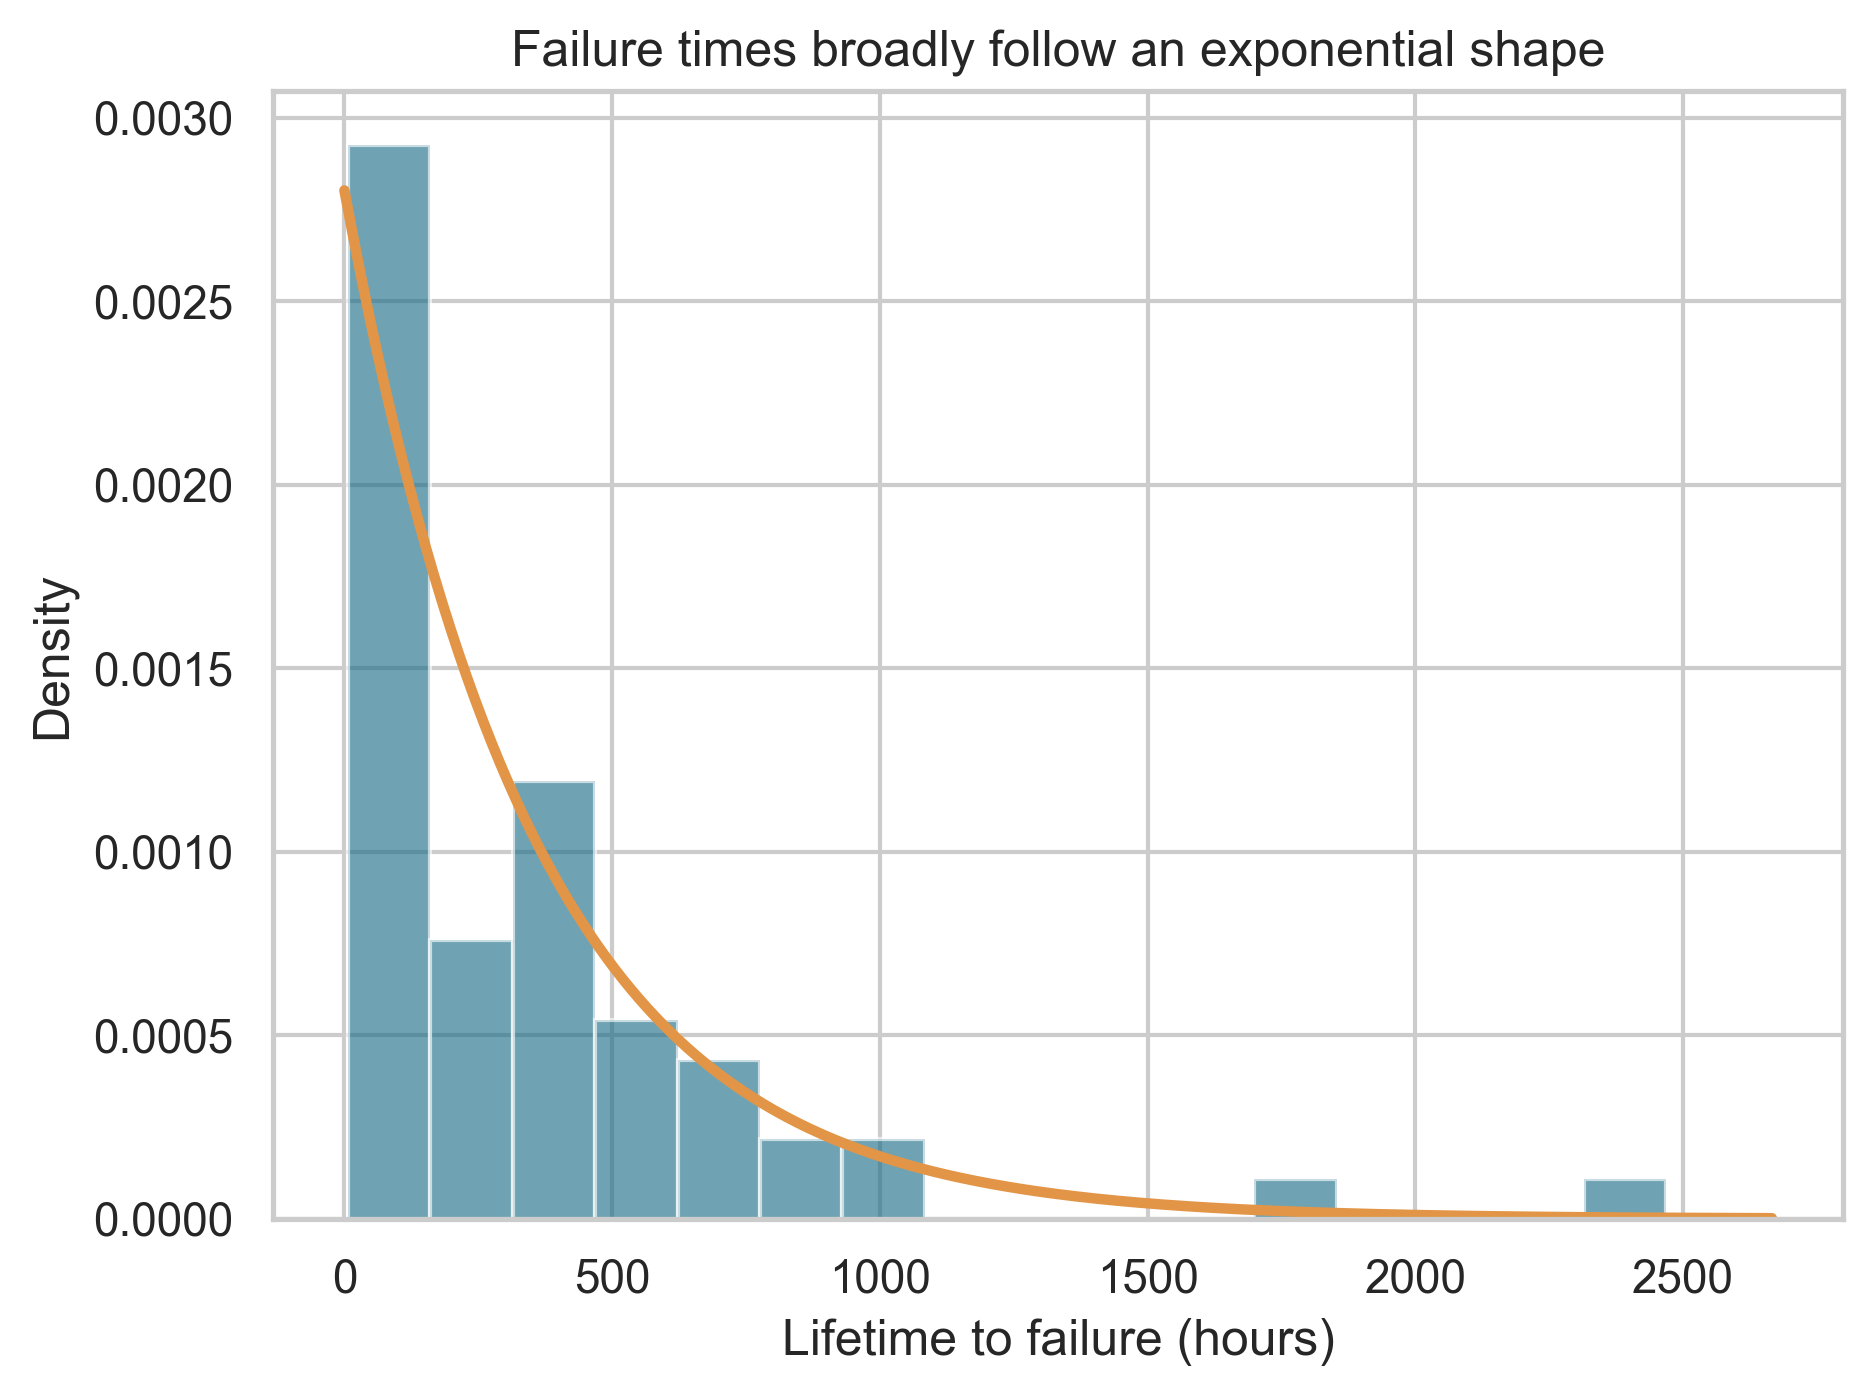

In [2]:
d=A['descriptive']
display(pd.DataFrame([d]).round(3))
display(Image(filename=str(FIG/'01_lifetime_histogram.png'), width=700))

### A2. Method of moments — from scratch

Equate $\bar X$ to $E[X]=\theta$. Therefore $\hat\theta_{MoM}=\bar X=\sum_iX_i/n$. The implementation in `theta_mom` uses base arithmetic; no fitting routine is in this answer path.

In [3]:
from src.estimation import theta_mom
print('MoM mean lifetime (hours):', A['theta_mom'])

MoM mean lifetime (hours): 356.95


### A3. Maximum likelihood — derivation and numerical check

For positive $x_i$, $\ell(\theta)=-n\log\theta-\sum_i x_i/\theta$. The score is $-n/\theta+\sum_i x_i/\theta^2$, so the stationary point is $\bar x$. The second derivative there is negative. `theta_mle` is closed form; the optimizer and `scipy.stats.expon.fit` run only in separate verification functions.

In [4]:
print('Closed-form MLE:',A['theta_mle'])
print('Numerical MLE check:',A['theta_numeric_verify'])
print('SciPy fit check:',A['theta_scipy_verify'])

Closed-form MLE: 356.95
Numerical MLE check: {'estimate': 356.95000000000005, 'optimizer_success': True, 'gradient_norm': 0.0}
SciPy fit check: 356.95000000000005


### A4. Analytical bias and 10,000-trial confirmation

Linearity gives $E[\hat\theta]=E[\bar X]=\theta$ and independence gives $\mathrm{Var}(\hat\theta)=\theta^2/n$. Simulate 10,000 new samples of 60 components from Exponential($\hat\theta$). The plug-in value is a simulation parameter, not a known physical truth.

,trials,mean estimate,empirical bias,empirical variance,theoretical variance
0,10000,356.683,-0.267,2084.362,2123.555


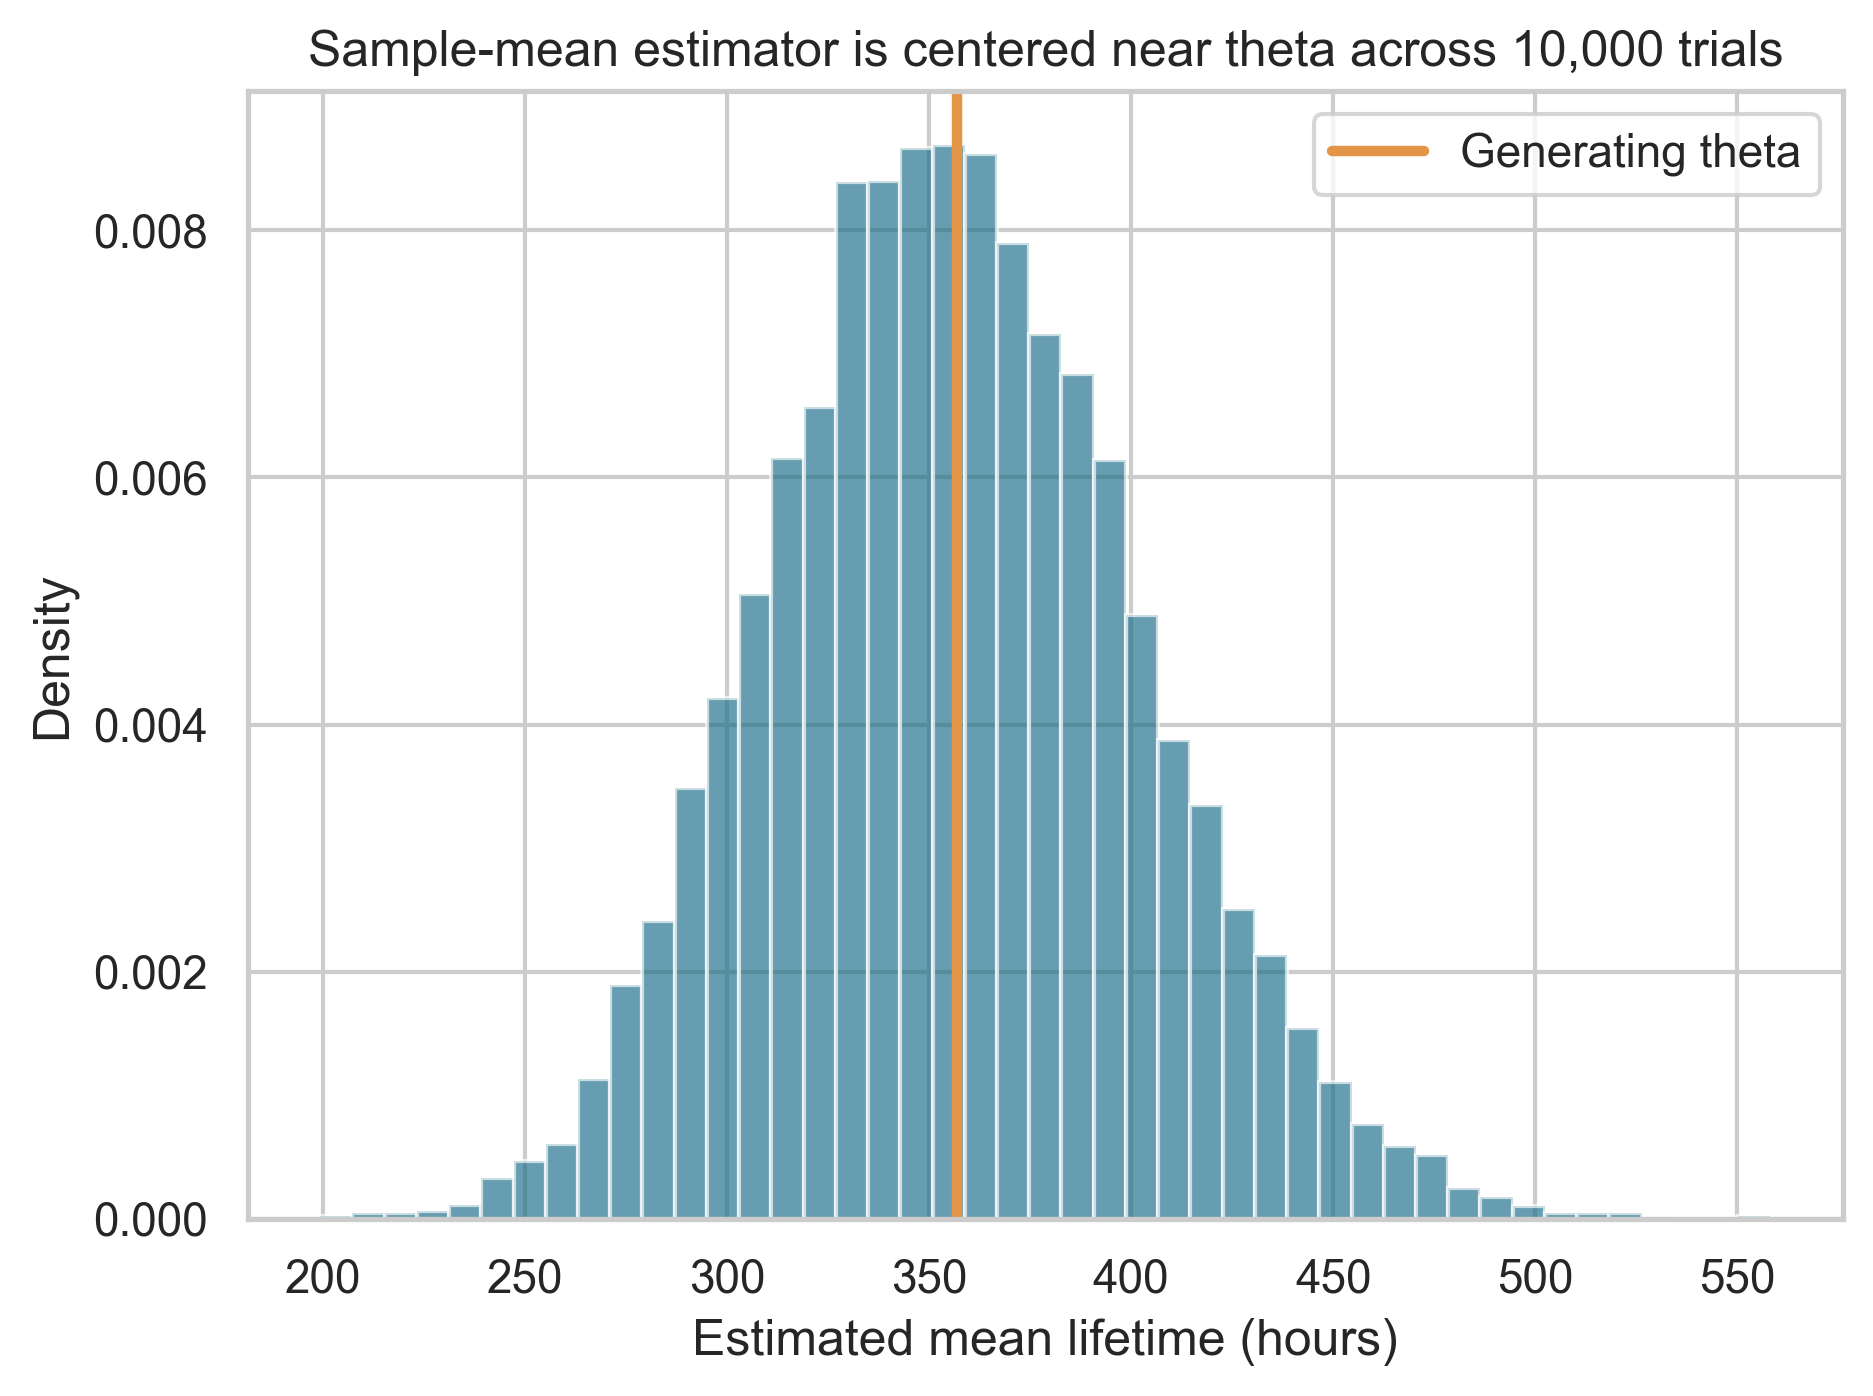

In [5]:
display(pd.DataFrame([{'trials':A['mc_bias_trials'],'mean estimate':A['mc_estimate_mean'],
  'empirical bias':A['mc_bias'],'empirical variance':A['mc_variance'],
  'theoretical variance':A['theoretical_variance']}]).round(3))
display(Image(filename=str(FIG/'02_estimator_mc.png'), width=700))

### A5. Consistency and asymptotic normality

For $n\in\{10,50,200,1000,5000\}$, 3,000 samples per size estimate variance. Theoretical variance $\theta^2/n\to0$, and unbiasedness then gives consistency in probability. At n = 5,000, standardize estimates by $\theta/\sqrt n$ and inspect a normal Q–Q plot.

Asymptotic Q-Q R²: 0.999475


,n,empirical_variance,theoretical_variance,empirical_bias
0,10,12771.634,12741.330,0.066
1,50,2503.263,2548.266,-0.440
2,200,650.906,637.067,-0.031
3,1000,124.364,127.413,0.322
4,5000,25.365,25.483,-0.036


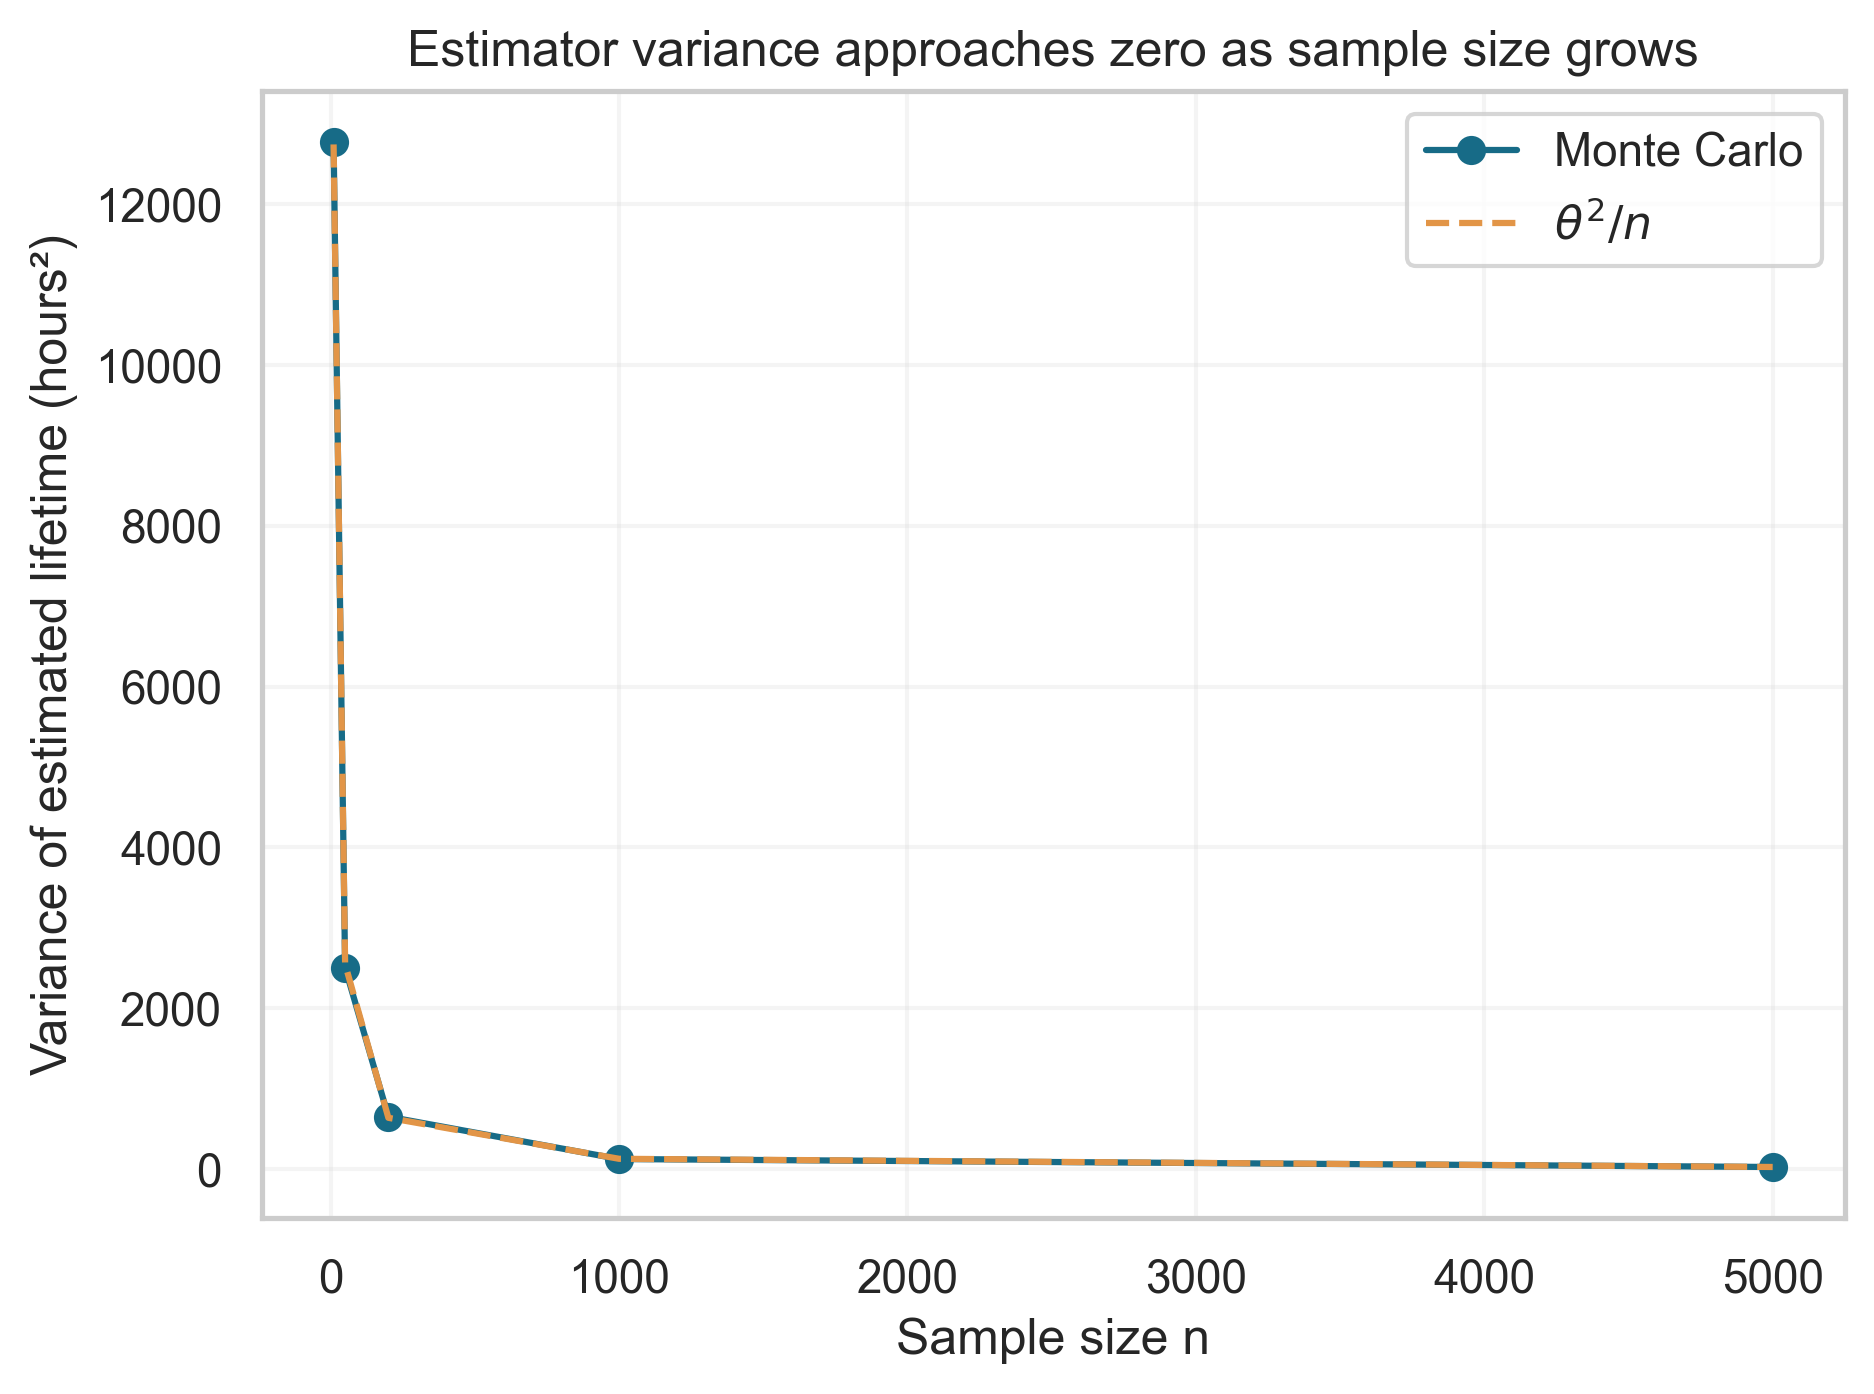

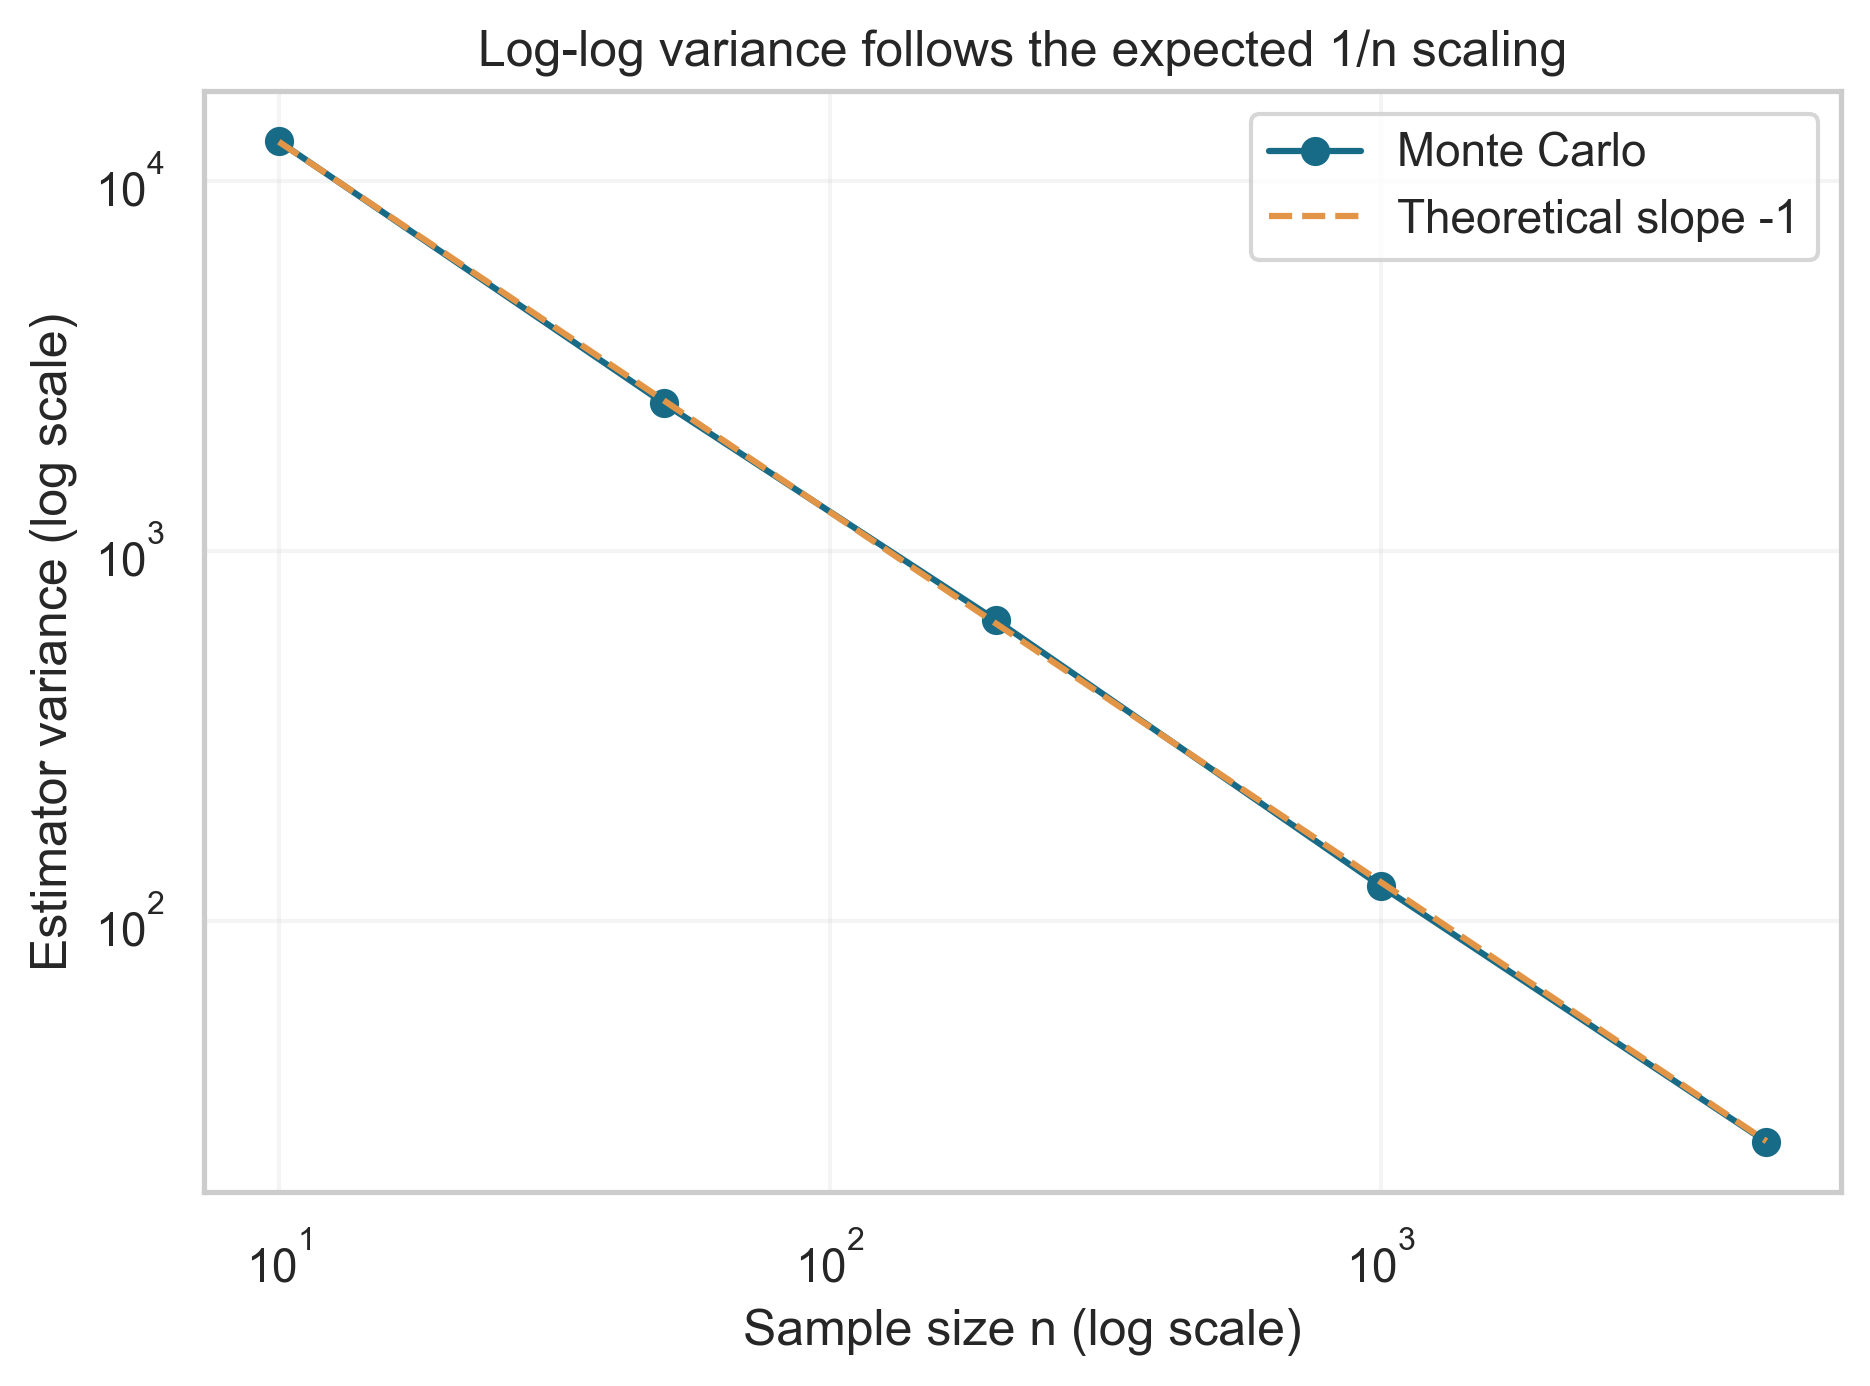

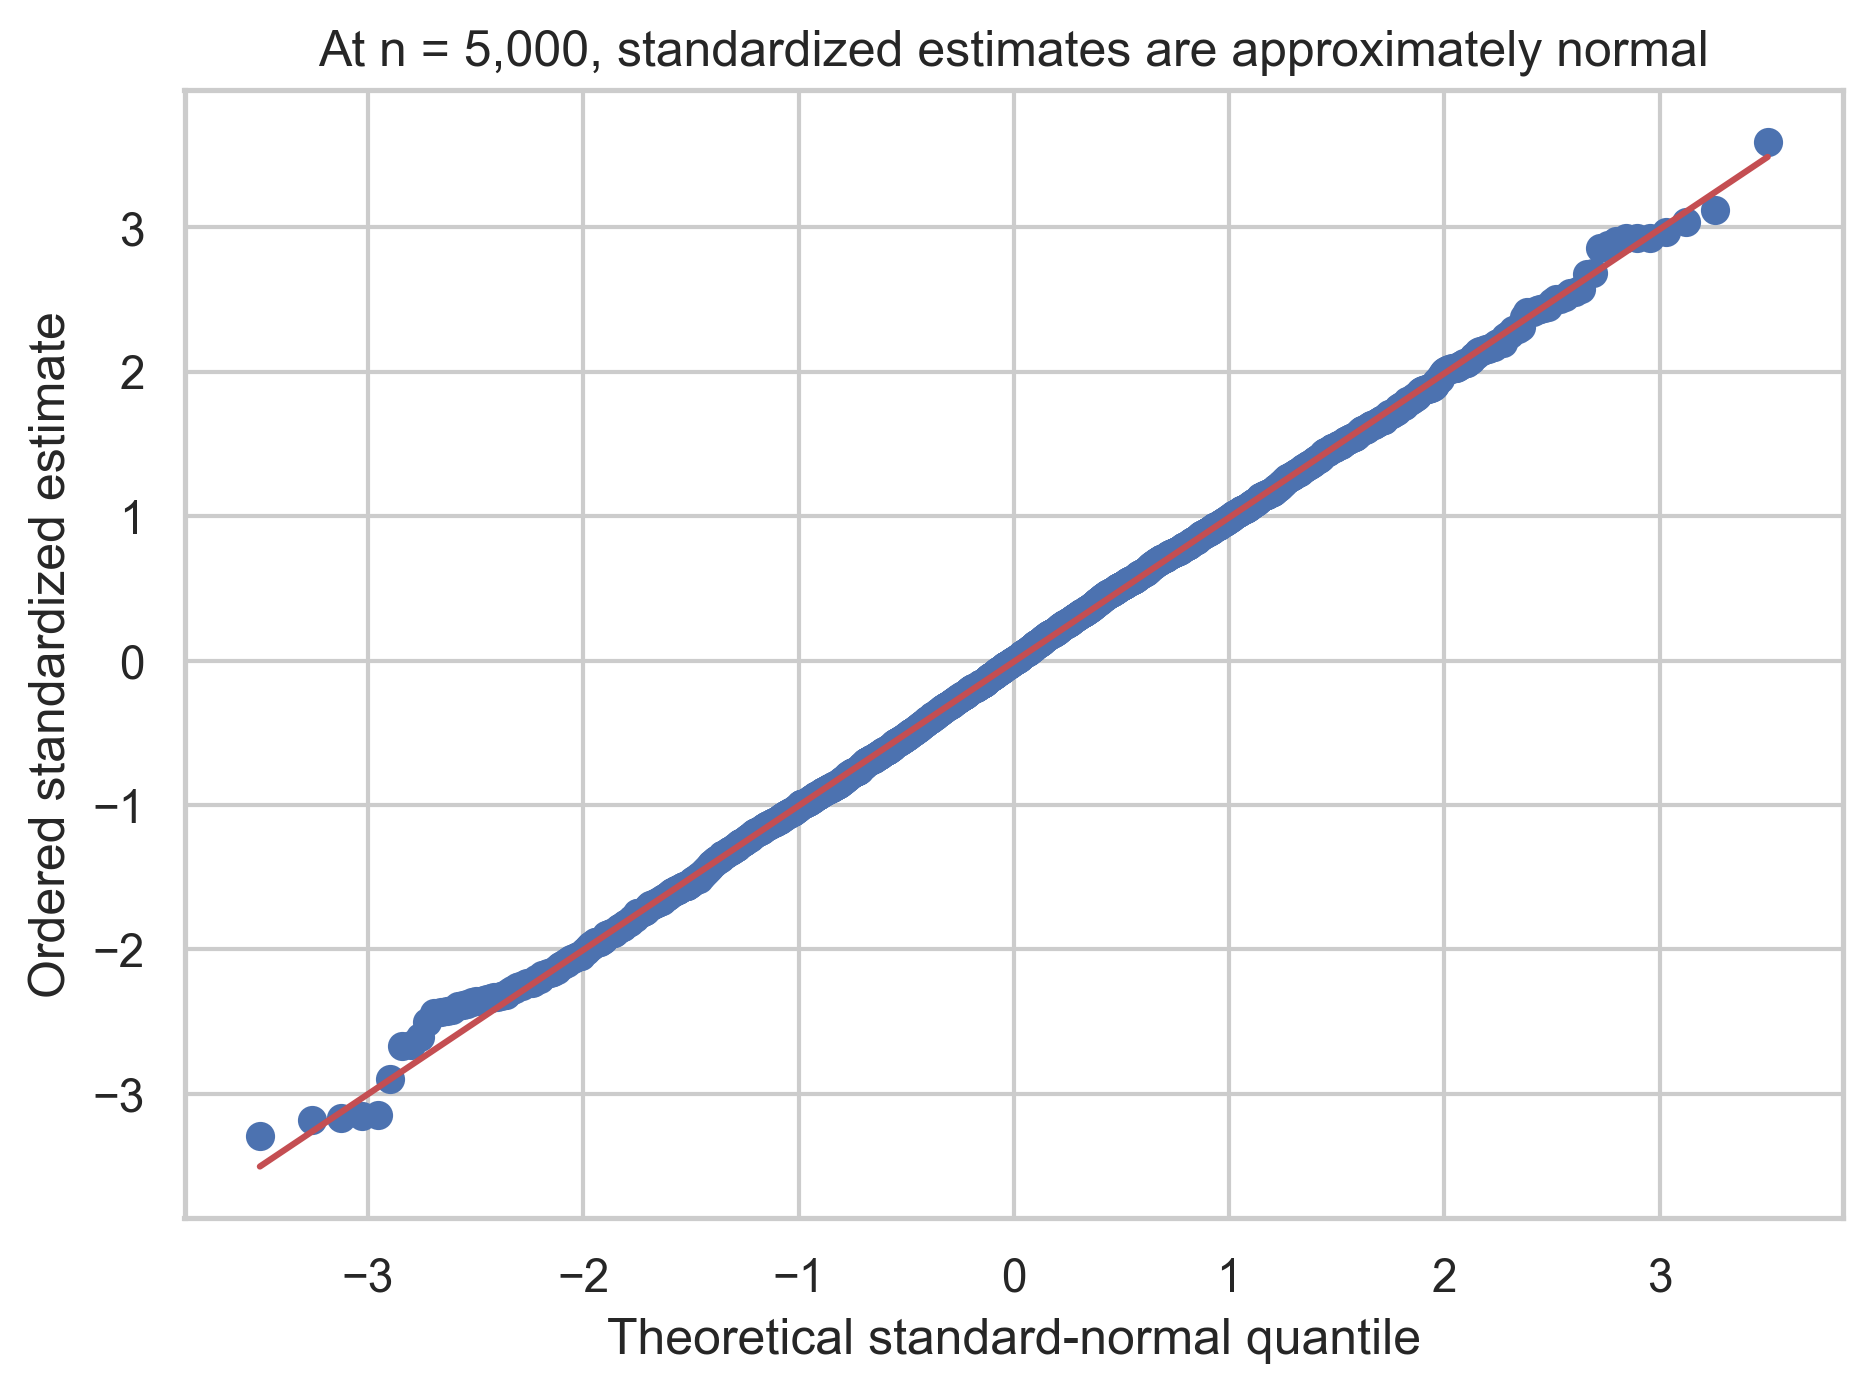

In [6]:
display(pd.DataFrame(A['consistency']).round(3))
print('Asymptotic Q-Q R²:',round(A['asymptotic_qq_r2'],6))
for name in ['03_consistency','04_consistency_loglog','05_asymptotic_qq']:
    display(Image(filename=str(FIG/f'{name}.png'),width=720))

### A6. Cramér–Rao bound and efficiency

For one exponential observation, Fisher information is $I_1(\theta)=1/\theta^2$; for n independent observations, $I_n=n/\theta^2$. The unbiased-estimator bound is $\theta^2/n$. The exact variance of $\bar X$ equals that bound, so theoretical efficiency is 1. The Monte Carlo ratio can drift slightly above 1 due to finite simulation error.

CRLB (hours²): 2123.555
Monte Carlo variance (hours²): 2084.362
CRLB / Monte Carlo variance: 1.0188


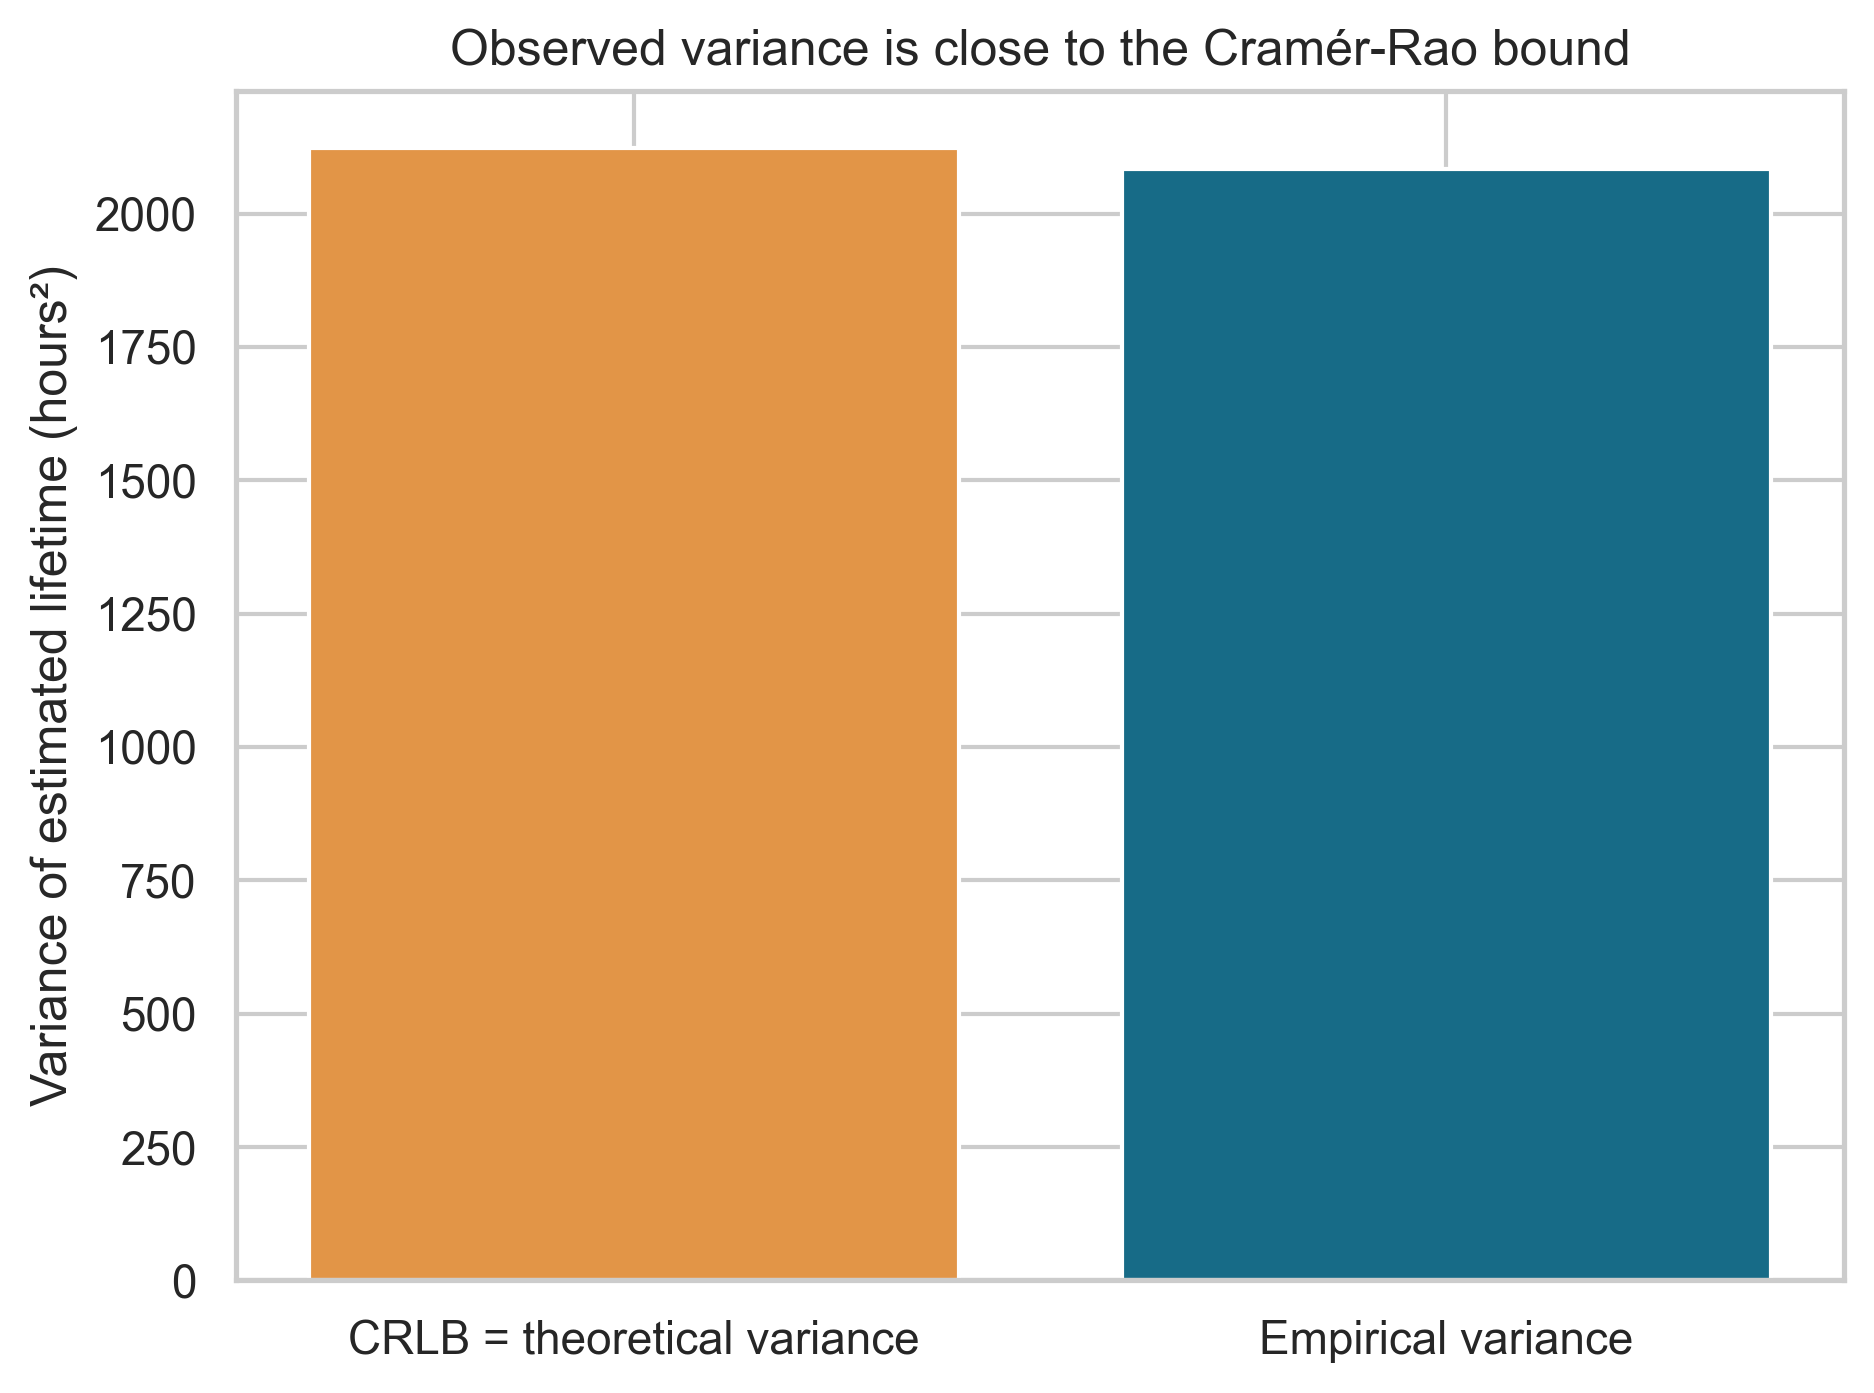

In [7]:
print('CRLB (hours²):',round(A['crlb'],3))
print('Monte Carlo variance (hours²):',round(A['mc_variance'],3))
print('CRLB / Monte Carlo variance:',round(A['efficiency'],4))
display(Image(filename=str(FIG/'06_efficiency.png'),width=670))

### A7. Exact, bootstrap, and coverage-checked intervals

The pivot $2n\bar X/\theta\sim\chi^2_{2n}$ yields an exact two-sided 95% interval. A separate 5,000-resample nonparametric percentile bootstrap interval uses the observed 60 lifetimes. To assess coverage, 2,000 new 60-item datasets are generated from the plug-in exponential model; each gets an exact interval and a 1,000-resample bootstrap interval. The smaller bootstrap count in the coverage experiment is stated explicitly for computational feasibility.

Coverage experiment: {'trials': 2000, 'bootstrap_resamples_per_trial': 1000, 'exact_coverage': 0.951, 'bootstrap_coverage': 0.9375, 'exact_hits': 1902, 'bootstrap_hits': 1875}


,method,lower,upper,width
0,Exact pivot,281.411,467.760,186.349
1,Percentile bootstrap,261.169,476.962,215.793


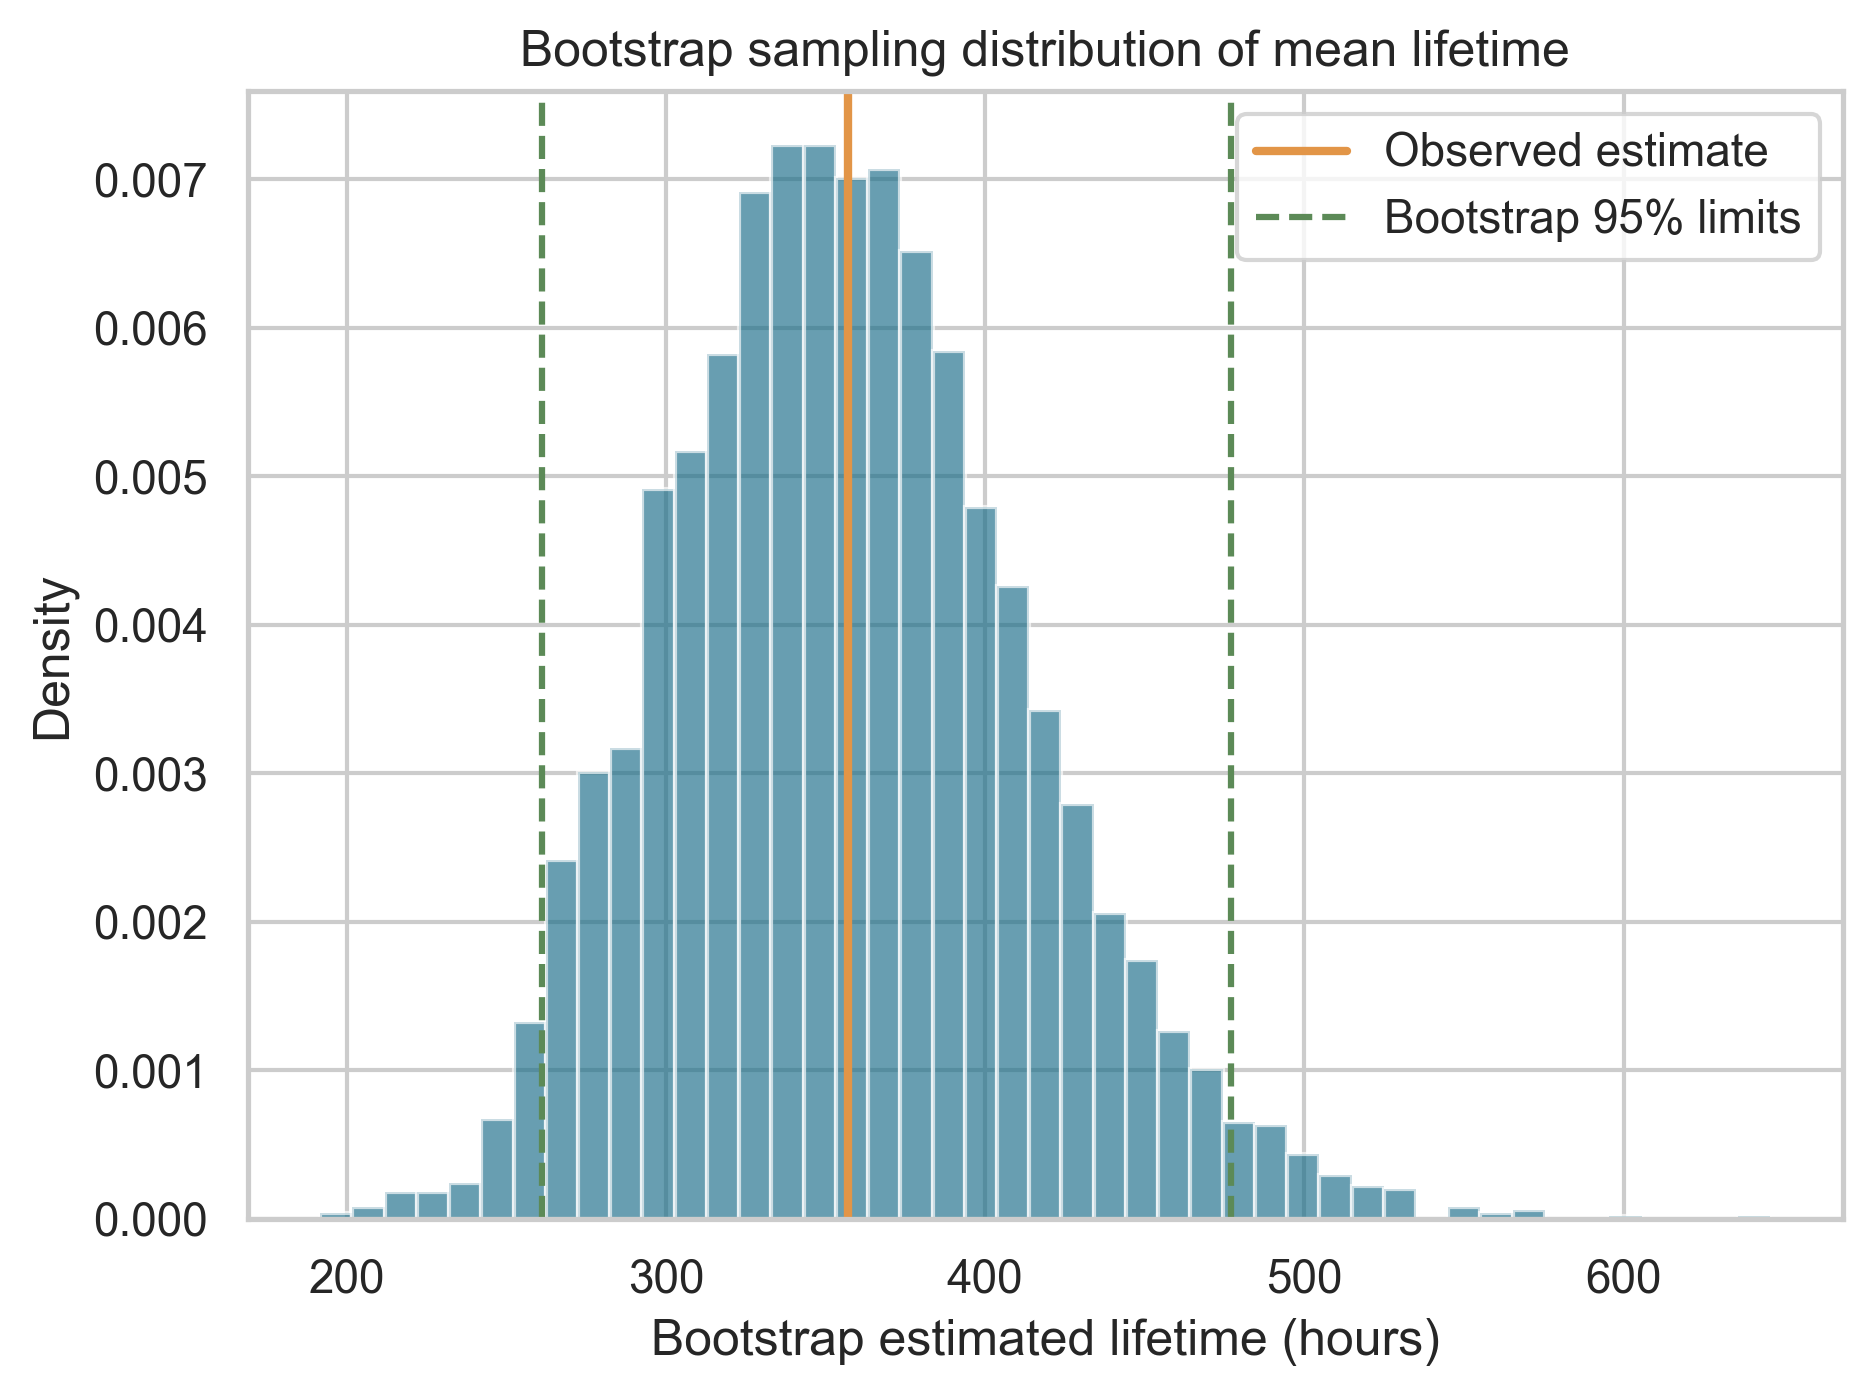

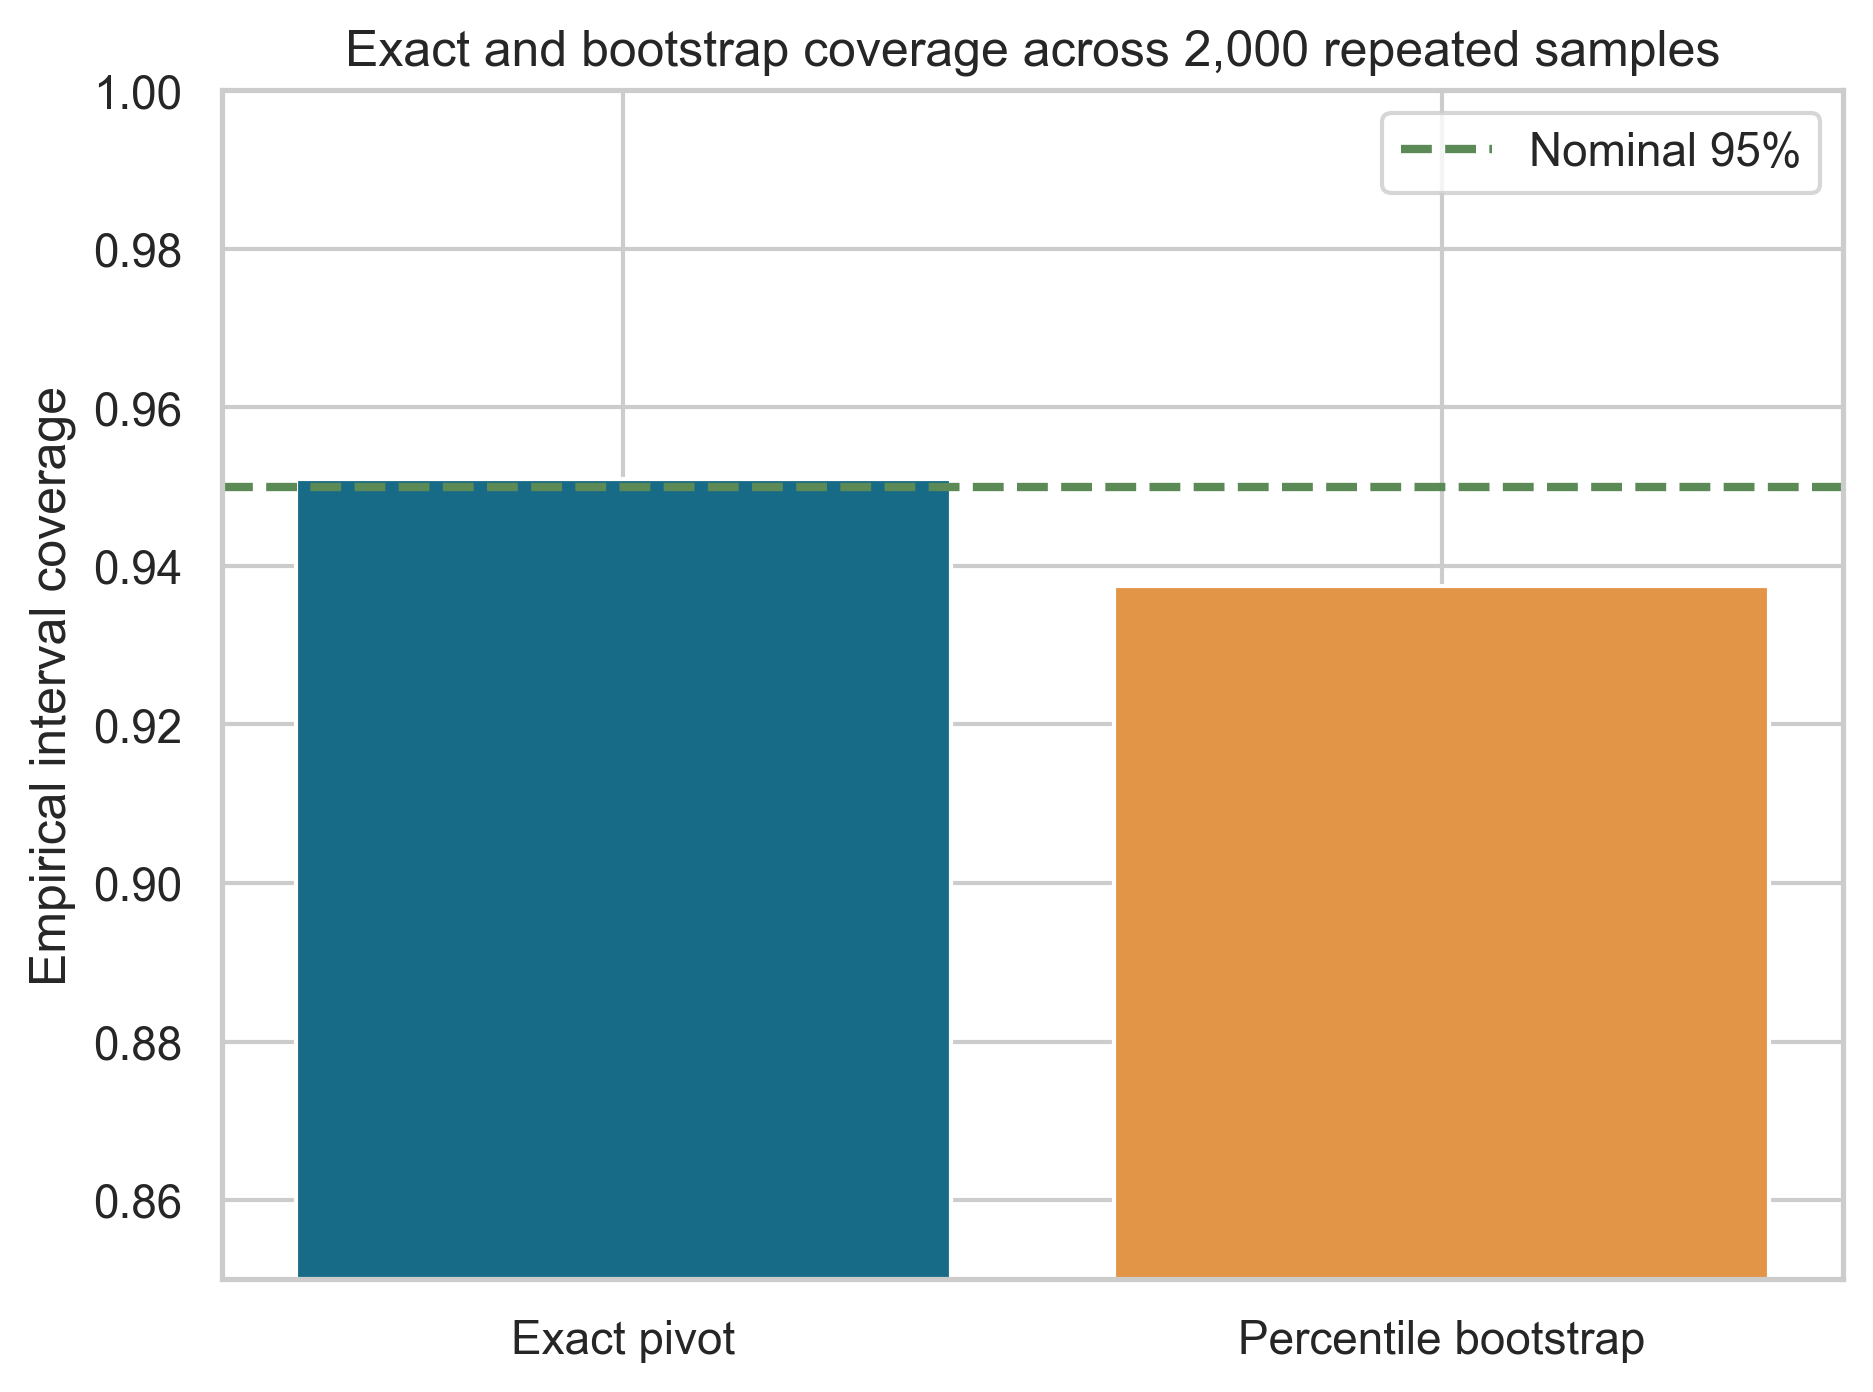

In [8]:
display(pd.DataFrame([{'method':'Exact pivot','lower':A['exact_ci'][0],
  'upper':A['exact_ci'][1],'width':A['exact_width']},
 {'method':'Percentile bootstrap','lower':A['bootstrap_ci'][0],
  'upper':A['bootstrap_ci'][1],'width':A['bootstrap_width']}]).round(3))
print('Coverage experiment:',A['coverage'])
for name in ['07_bootstrap_lifetime','08_coverage']:
    display(Image(filename=str(FIG/f'{name}.png'),width=700))

### A8. Reliability at 500 hours

By MLE invariance, $\hat R(500)=\exp(-500/\hat\theta)$. Transform the 5,000 bootstrap mean estimates by the same survival function to construct a percentile interval. Reliability is a model-based probability of surviving beyond 500 hours, not an observed fraction of this sample.

Estimated R(500): 0.24641
Bootstrap 95% CI: [0.14742, 0.35053]


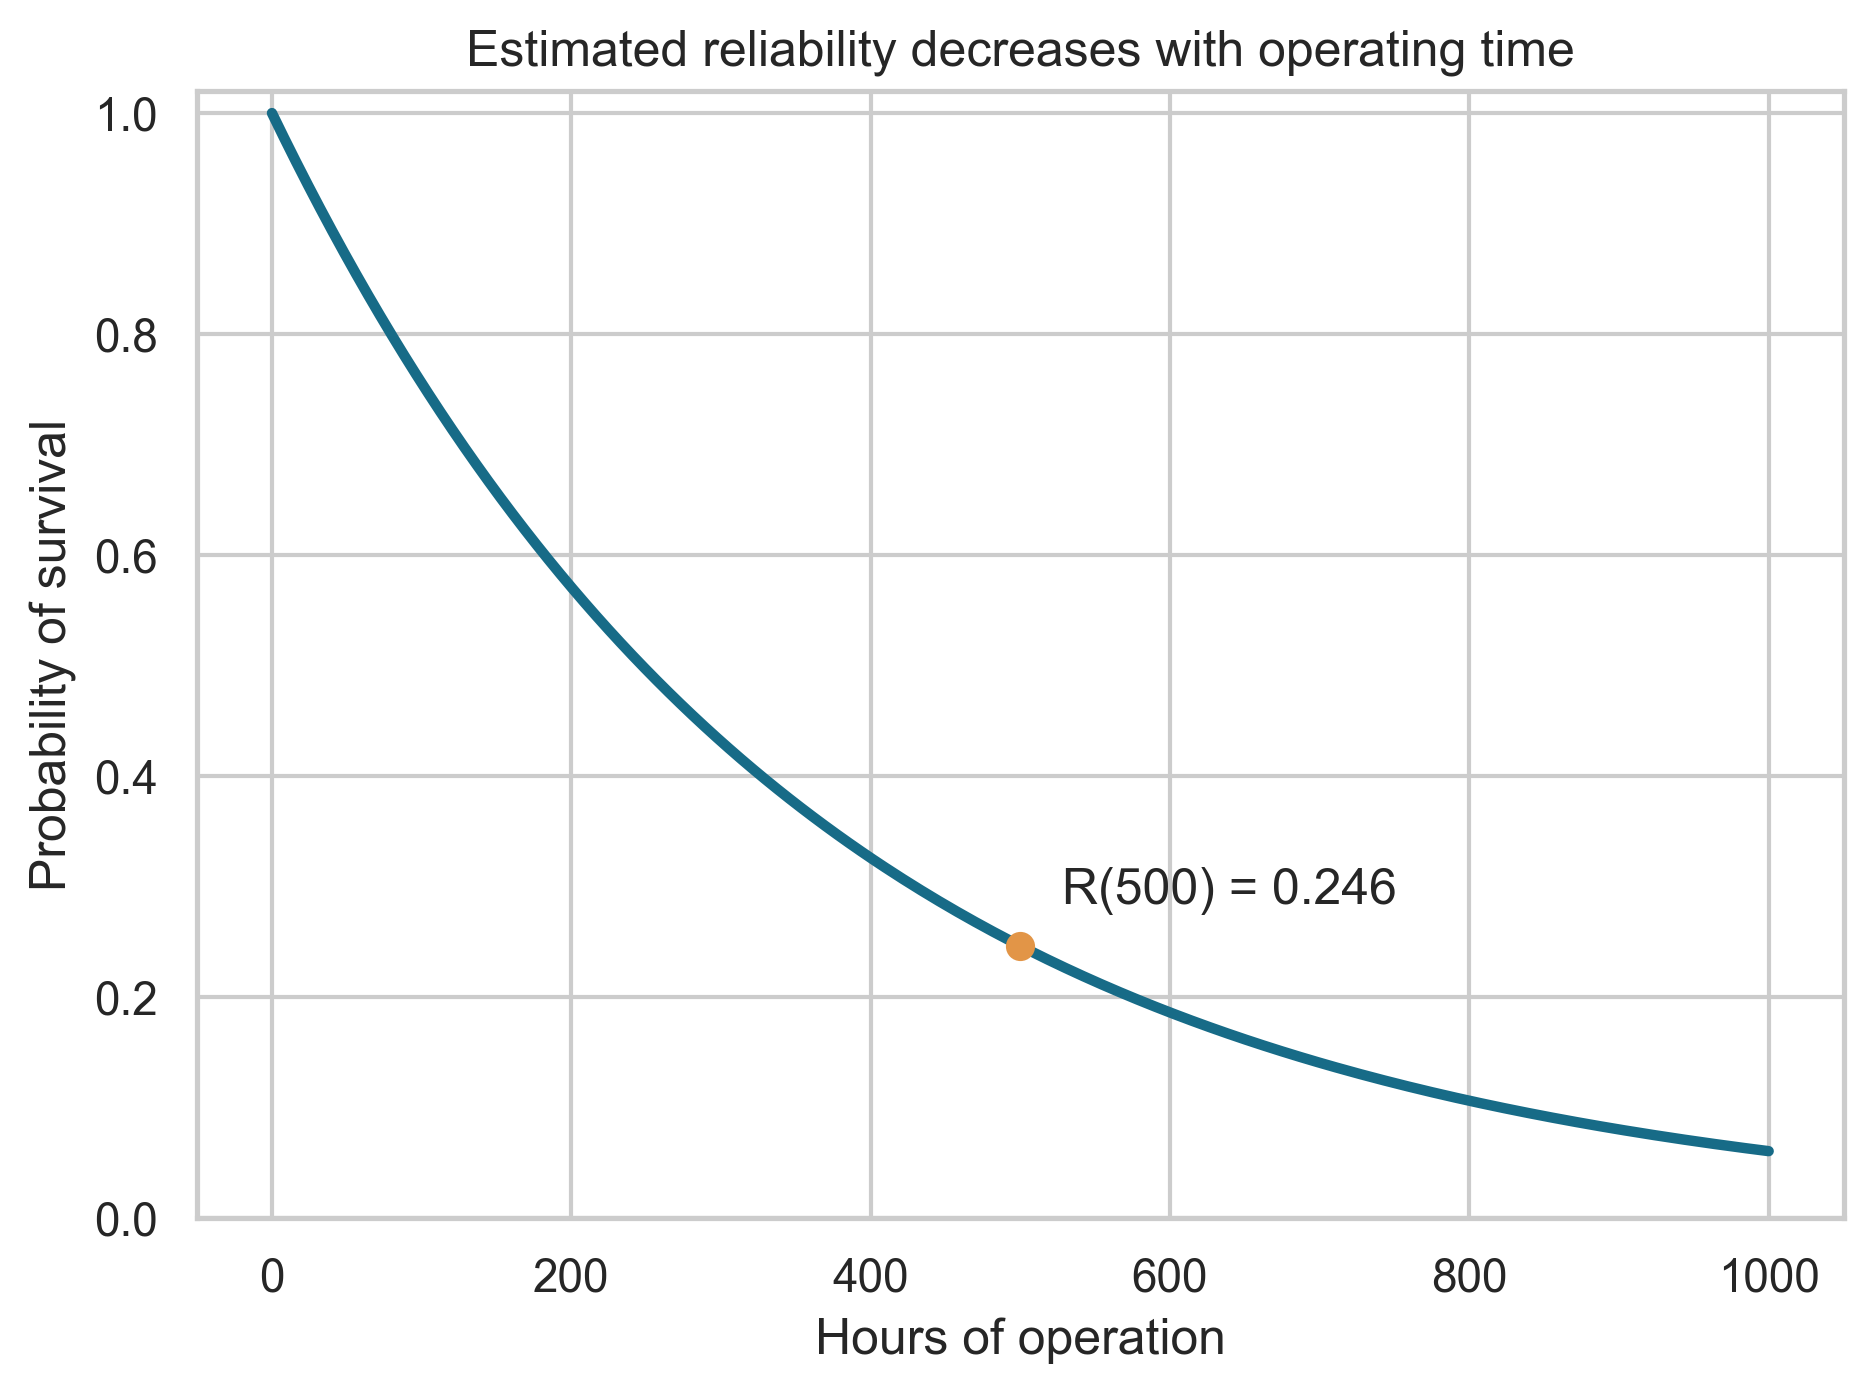

In [9]:
print('Estimated R(500):',round(A['reliability_500'],5))
print('Bootstrap 95% CI:',[round(v,5) for v in A['reliability_bootstrap_ci']])
display(Image(filename=str(FIG/'09_reliability.png'),width=700))

# Part B | Temperature and hardness regression

Assumed model: $Y_i=A+B x_i+\varepsilon_i$ with independent Gaussian errors of common variance. Temperature is measured in °C and hardness in HV. The file order is temperature sorted, so Durbin–Watson is descriptive and cannot be treated as a time-series independence test.

### B1. Scatter and linearity

Plot hardness against temperature and inspect whether a straight line captures the main trend. Curvature or increasing spread would weaken the simple-model assumptions.

Temperature range (°C): 172.0 553.0


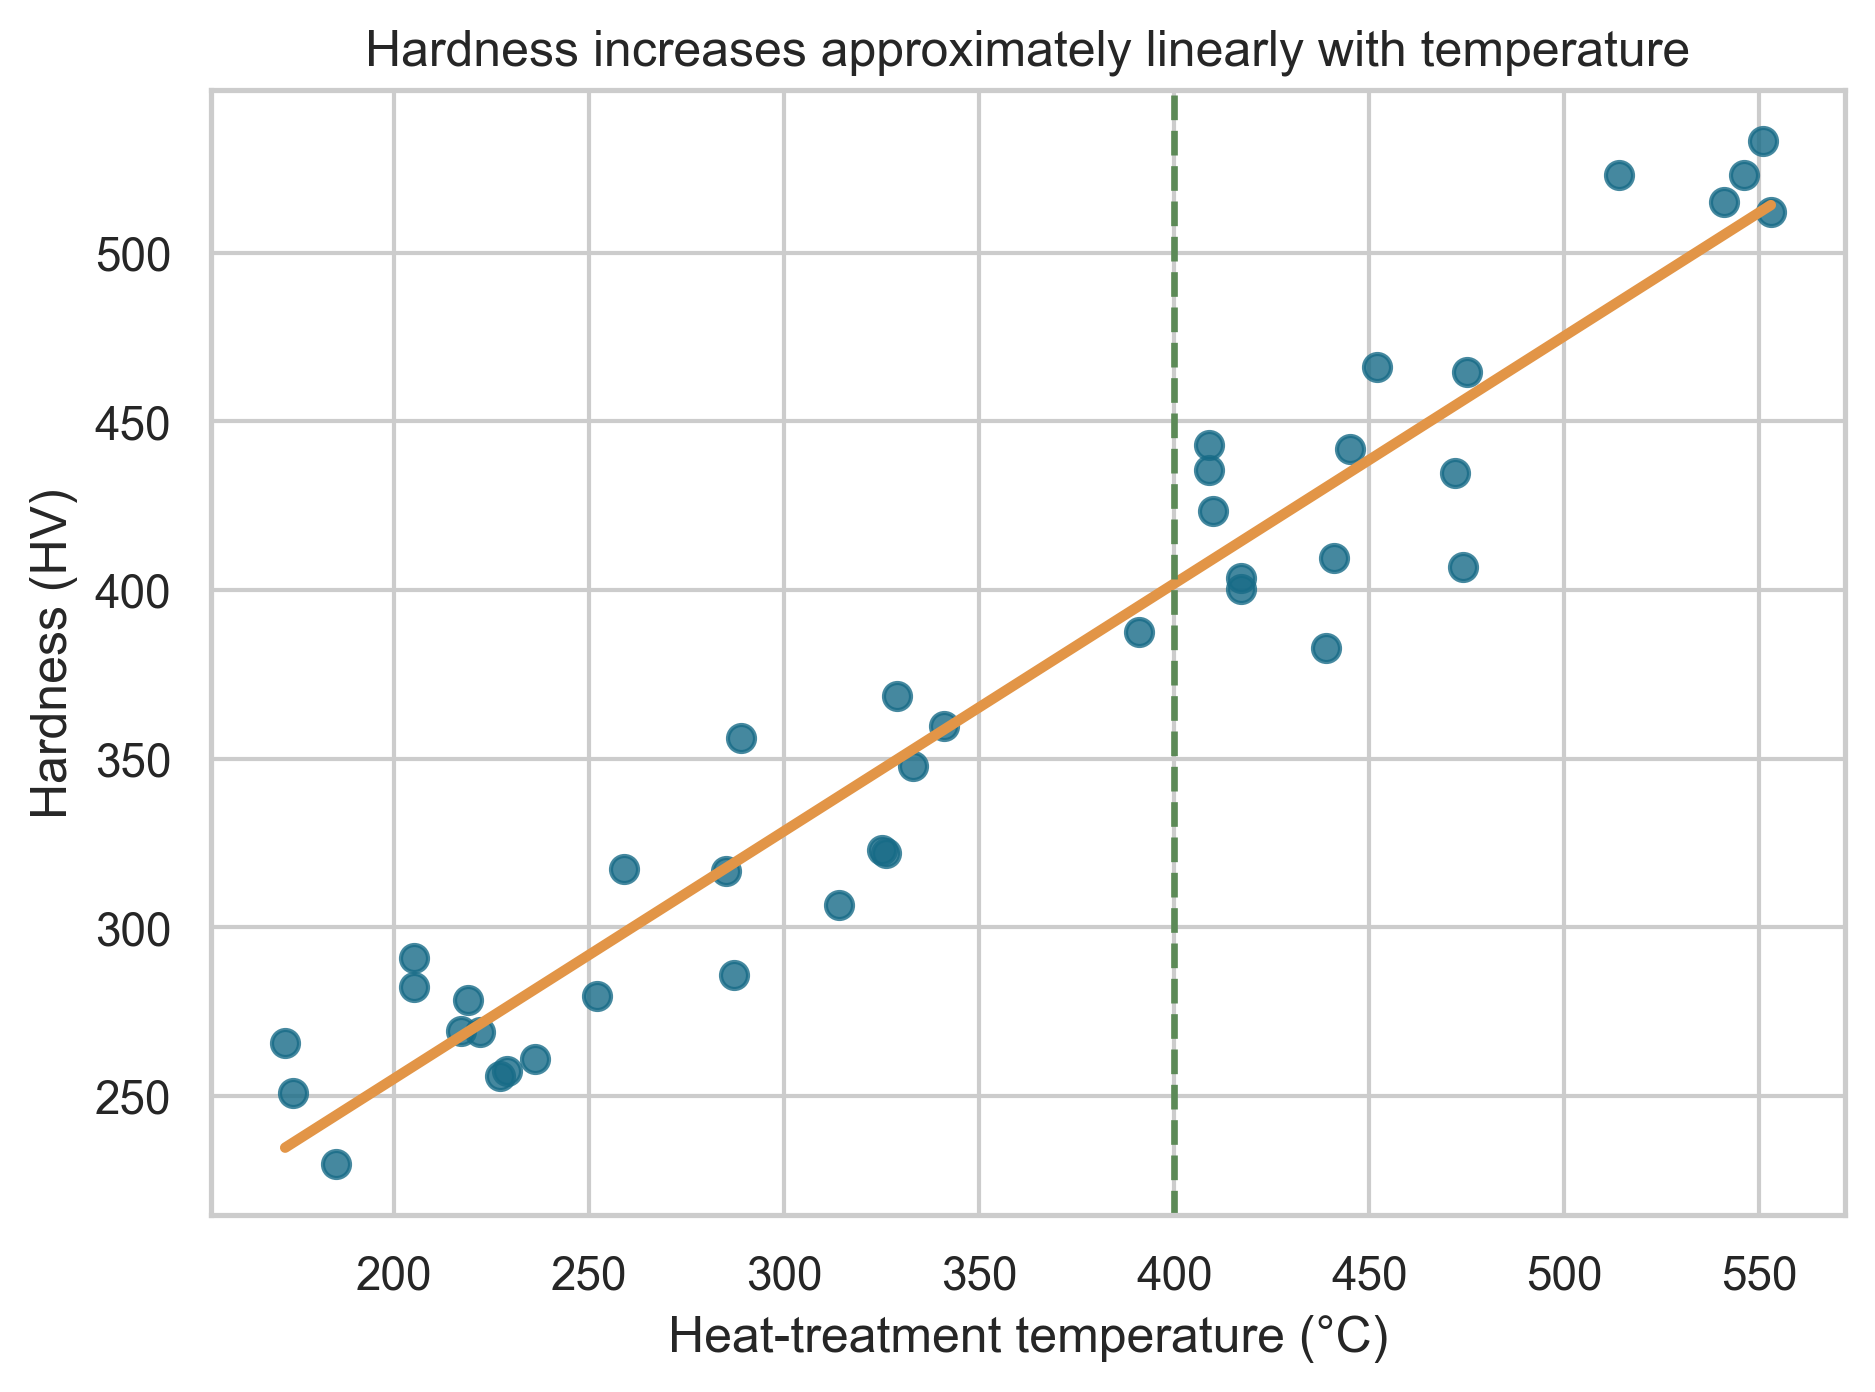

In [10]:
print('Temperature range (°C):',B['temperature_min'],B['temperature_max'])
display(Image(filename=str(FIG/'10_process_fit.png'),width=740))

### B2. Least squares from the normal equations

Compute $S_{xx}=\sum(x_i-\bar x)^2$ and $S_{xy}=\sum(x_i-\bar x)(y_i-\bar y)$ directly; then $b=S_{xy}/S_{xx}$ and $a=\bar y-b\bar x$. `ols_fit` is the answer path. SciPy's `linregress` is used solely in `ols_linregress_verify`.

In [11]:
f=B['fit']
display(pd.DataFrame([{'Sxx':f['sxx'],'Sxy':f['sxy'],'intercept a':f['a'],
  'slope b (HV/°C)':f['b']}]).round(5))
print('Independent library check:',B['linregress_verify'])

Independent library check: {'a': 108.60233873741691, 'b': 0.7333171123545665, 'r2': 0.9338047246783259}


,Sxx,Sxy,intercept a,slope b (HV/°C)
0,545178.775,399788.925,108.60234,0.73332


### B3. Why Gaussian MLE equals LSE

For normal errors, $\ell(A,B,\sigma^2)=-\frac n2\log(2\pi\sigma^2)-SSE(A,B)/(2\sigma^2)$. For fixed positive variance, maximizing this log likelihood in A and B is equivalent to minimizing SSE. The score equations are the least-squares normal equations. A generic numerical optimizer fits centered intercept, scaled slope, and log sigma, then transforms coefficients back.

In [12]:
print('Custom LSE coefficients:',f['a'],f['b'])
print('Numerical Gaussian MLE check:',B['gaussian_mle_numeric_verify'])
print('Coefficient agreement tolerance: 1e-5')

Custom LSE coefficients: 108.60233873741686 0.7333171123545666
Numerical Gaussian MLE check: {'a': 108.60233873741777, 'b': 0.7333171123545641, 'sigma2_mle': 519.557374191599, 'optimizer_success': True, 'gradient_norm': 7.181559586684001e-13}
Coefficient agreement tolerance: 1e-5


### B4. Error variance and residual scale

Residuals are $e_i=y_i-a-bx_i$. The unbiased error-variance estimate divides $SSE=\sum e_i^2$ by $n-2$; residual standard error $s=\sqrt{s^2}$ is measured in HV. The Gaussian MLE of variance divides by n and is therefore numerically different, even though its coefficient MLEs equal LSE.

In [13]:
print('SSE:',round(f['sse'],3),'HV²')
print('Unbiased s²:',round(f['s2'],3),'HV²')
print('Residual standard error s:',round(f['s'],3),'HV')
print('Gaussian MLE sigma²:',round(B['gaussian_mle_numeric_verify']['sigma2_mle'],3),'HV²')

SSE: 20782.295 HV²
Unbiased s²: 546.902 HV²
Residual standard error s: 23.386 HV
Gaussian MLE sigma²: 519.557 HV²


### B5. Confidence intervals and slope test

Using $t_{n-2}$, compute 95% CIs for A and B from course standard-error formulas. Test $H_0:B=0$ versus $H_1:B\ne0$ at 5%. The slope is HV per 1 °C; the intercept is extrapolated to 0 °C and has little direct process meaning. A separate 10,000-trial plug-in Gaussian simulation checks direct-sum slope bias, variance, and 95% slope-interval coverage.

Slope test: t = 23.153 df = 38 p = 5.236122027201967e-24
Regression Monte Carlo: {'trials': 10000, 'intercept_bias': 0.14577529726000193, 'slope_bias': -0.0004342207571487178, 'intercept_variance_empirical': 134.97291237297222, 'intercept_variance_theoretical': 136.33176467121362, 'slope_variance_empirical': 0.0009944198773835428, 'slope_variance_theoretical': 0.0010031617594596226, 'slope_ci_coverage': 0.9525}


,parameter,estimate,SE,CI lower,CI upper
0,Intercept A,108.60234,11.67612,84.96527,132.23941
1,Slope B,0.73332,0.03167,0.66920,0.79744


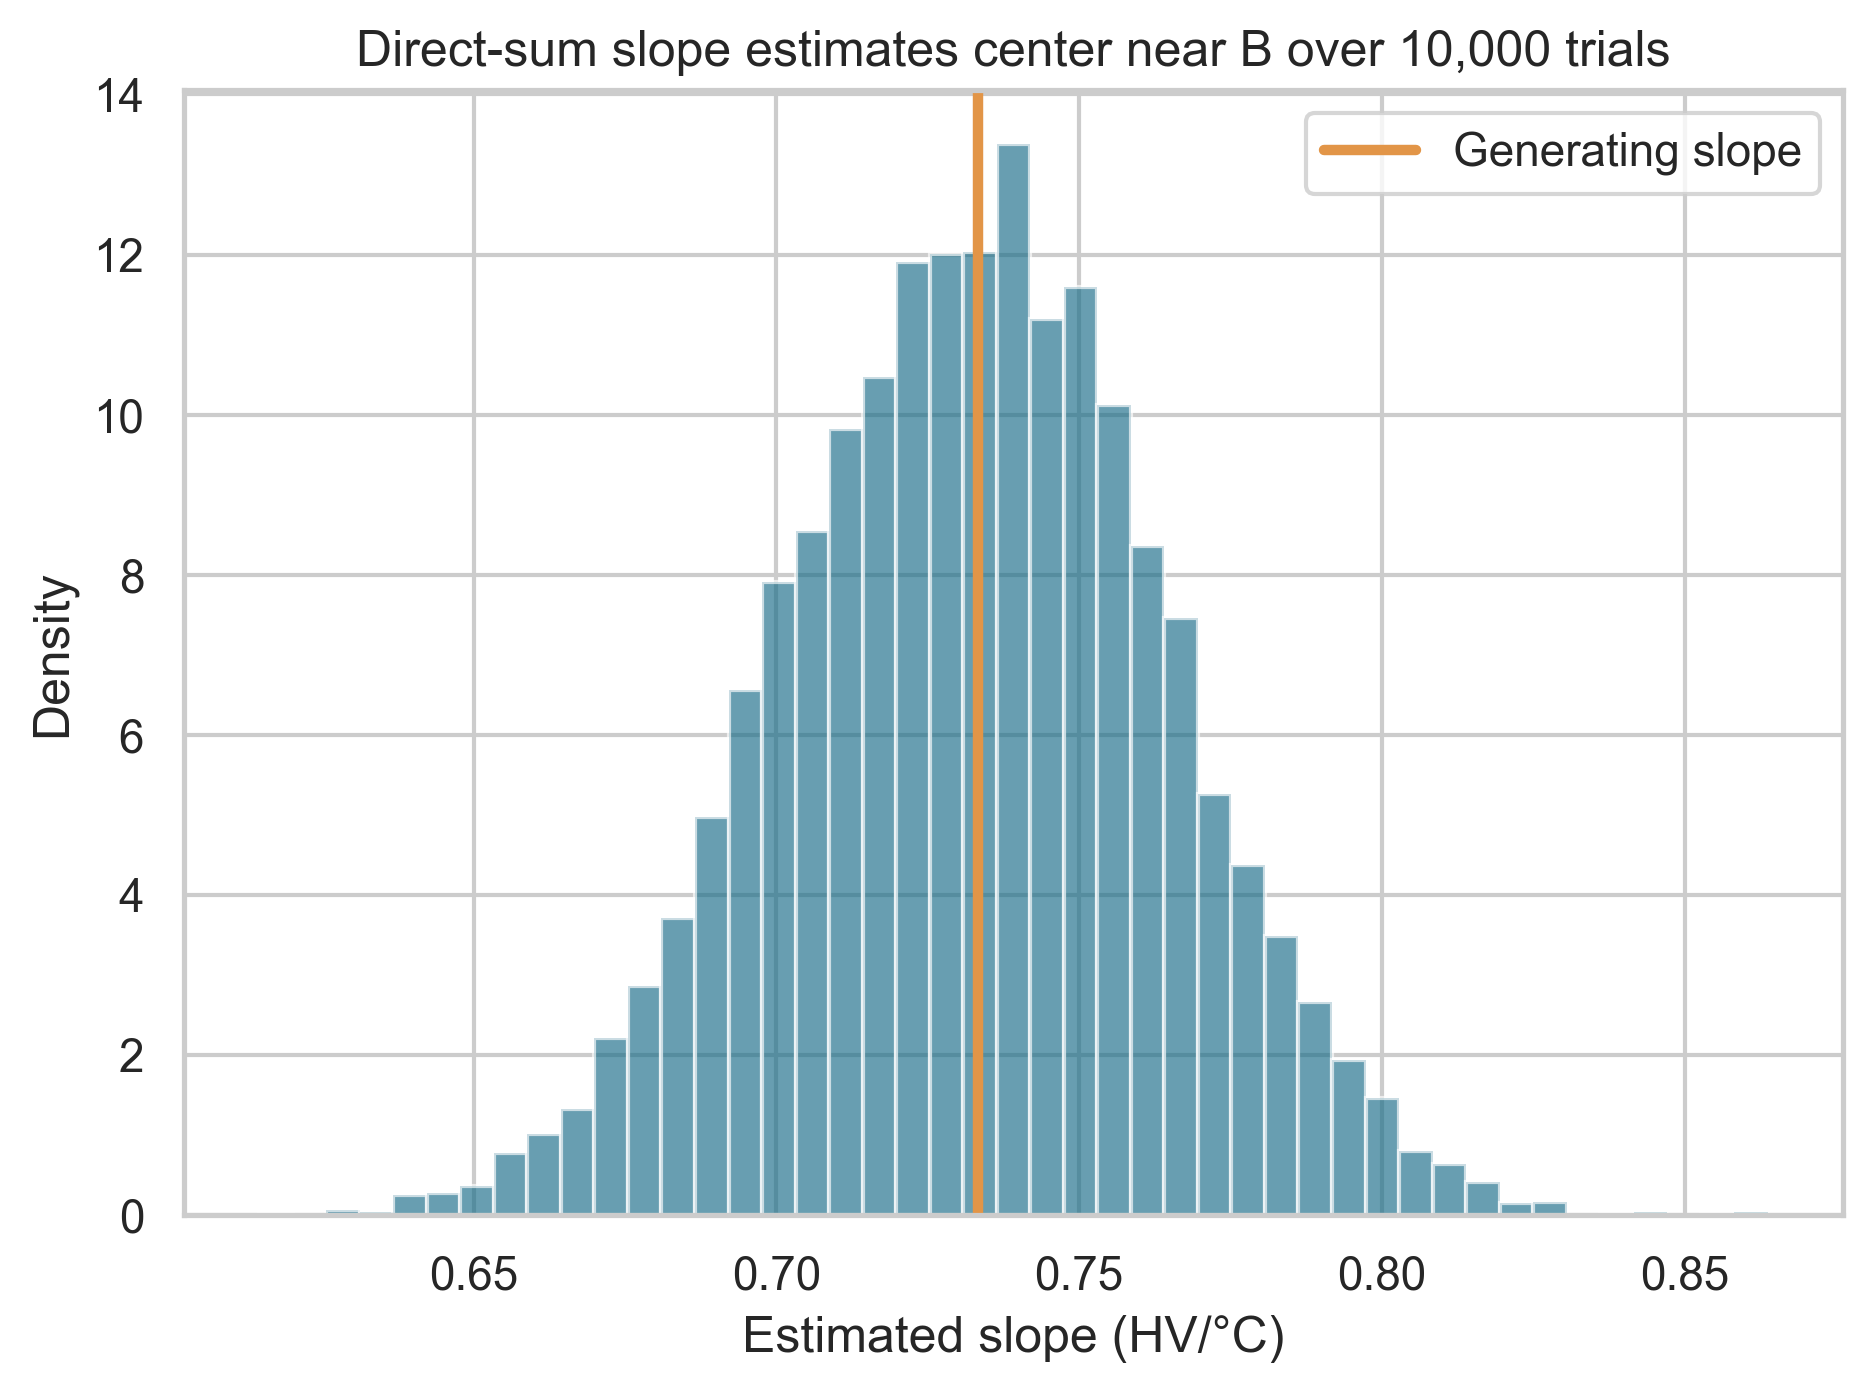

In [14]:
i=B['inference']
display(pd.DataFrame([{'parameter':'Intercept A','estimate':f['a'],'SE':i['se_a'],
 'CI lower':i['a_ci'][0],'CI upper':i['a_ci'][1]},
 {'parameter':'Slope B','estimate':f['b'],'SE':i['se_b'],
 'CI lower':i['b_ci'][0],'CI upper':i['b_ci'][1]}]).round(5))
print('Slope test: t =',round(i['slope_t'],4),'df =',i['df'],'p =',i['slope_p'])
print('Regression Monte Carlo:',B['monte_carlo'])
display(Image(filename=str(FIG/'14_regression_mc.png'),width=700))

### B6. Coefficient of determination

Calculate $R^2=1-SSE/S_{yy}$ from direct sums. It describes the fraction of in-sample hardness variation captured by this line; it does not prove causation or model adequacy.

In [15]:
print('Syy:',round(f['syy'],3),'HV²')
print('R²:',round(f['r2'],5),'= ',round(100*f['r2'],2),'% of sample variation')

Syy: 313954.355 HV²
R²: 0.9338 =  93.38 % of sample variation


### B7. Residual diagnostics

Inspect residuals against fitted hardness and a normal Q–Q plot. Shapiro assesses residual normality; Breusch–Pagan regresses squared residuals on temperature and uses $nR^2$ with a chi-square(1) reference. Durbin–Watson is reported in the file's temperature order only, so it has no valid temporal interpretation.

Diagnostics: {'shapiro_w': 0.97115, 'shapiro_p': 0.391, 'bp_lm': 0.54603, 'bp_p': 0.45995, 'durbin_watson': 1.59334}


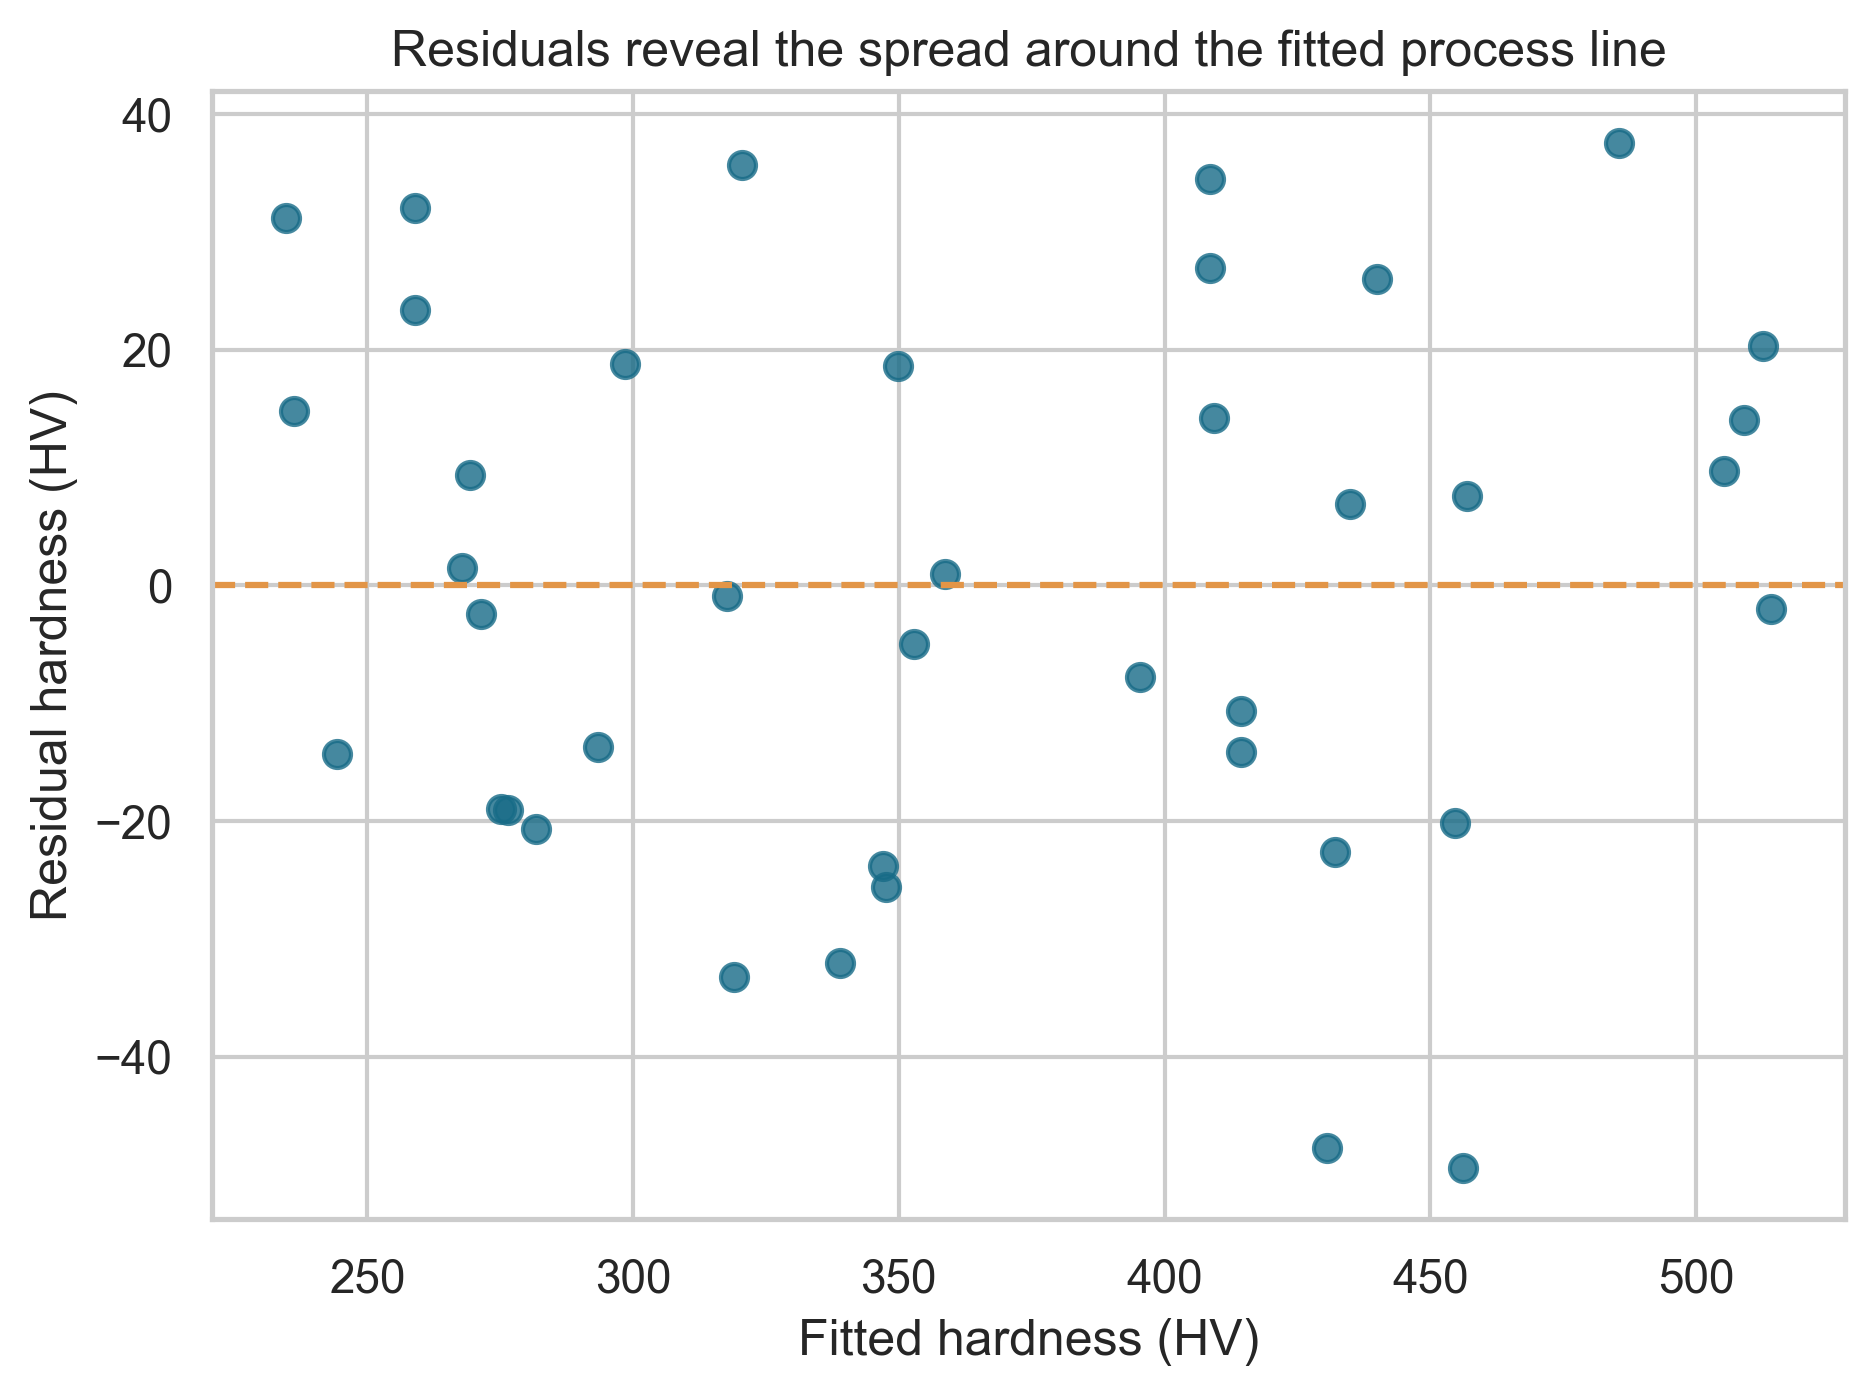

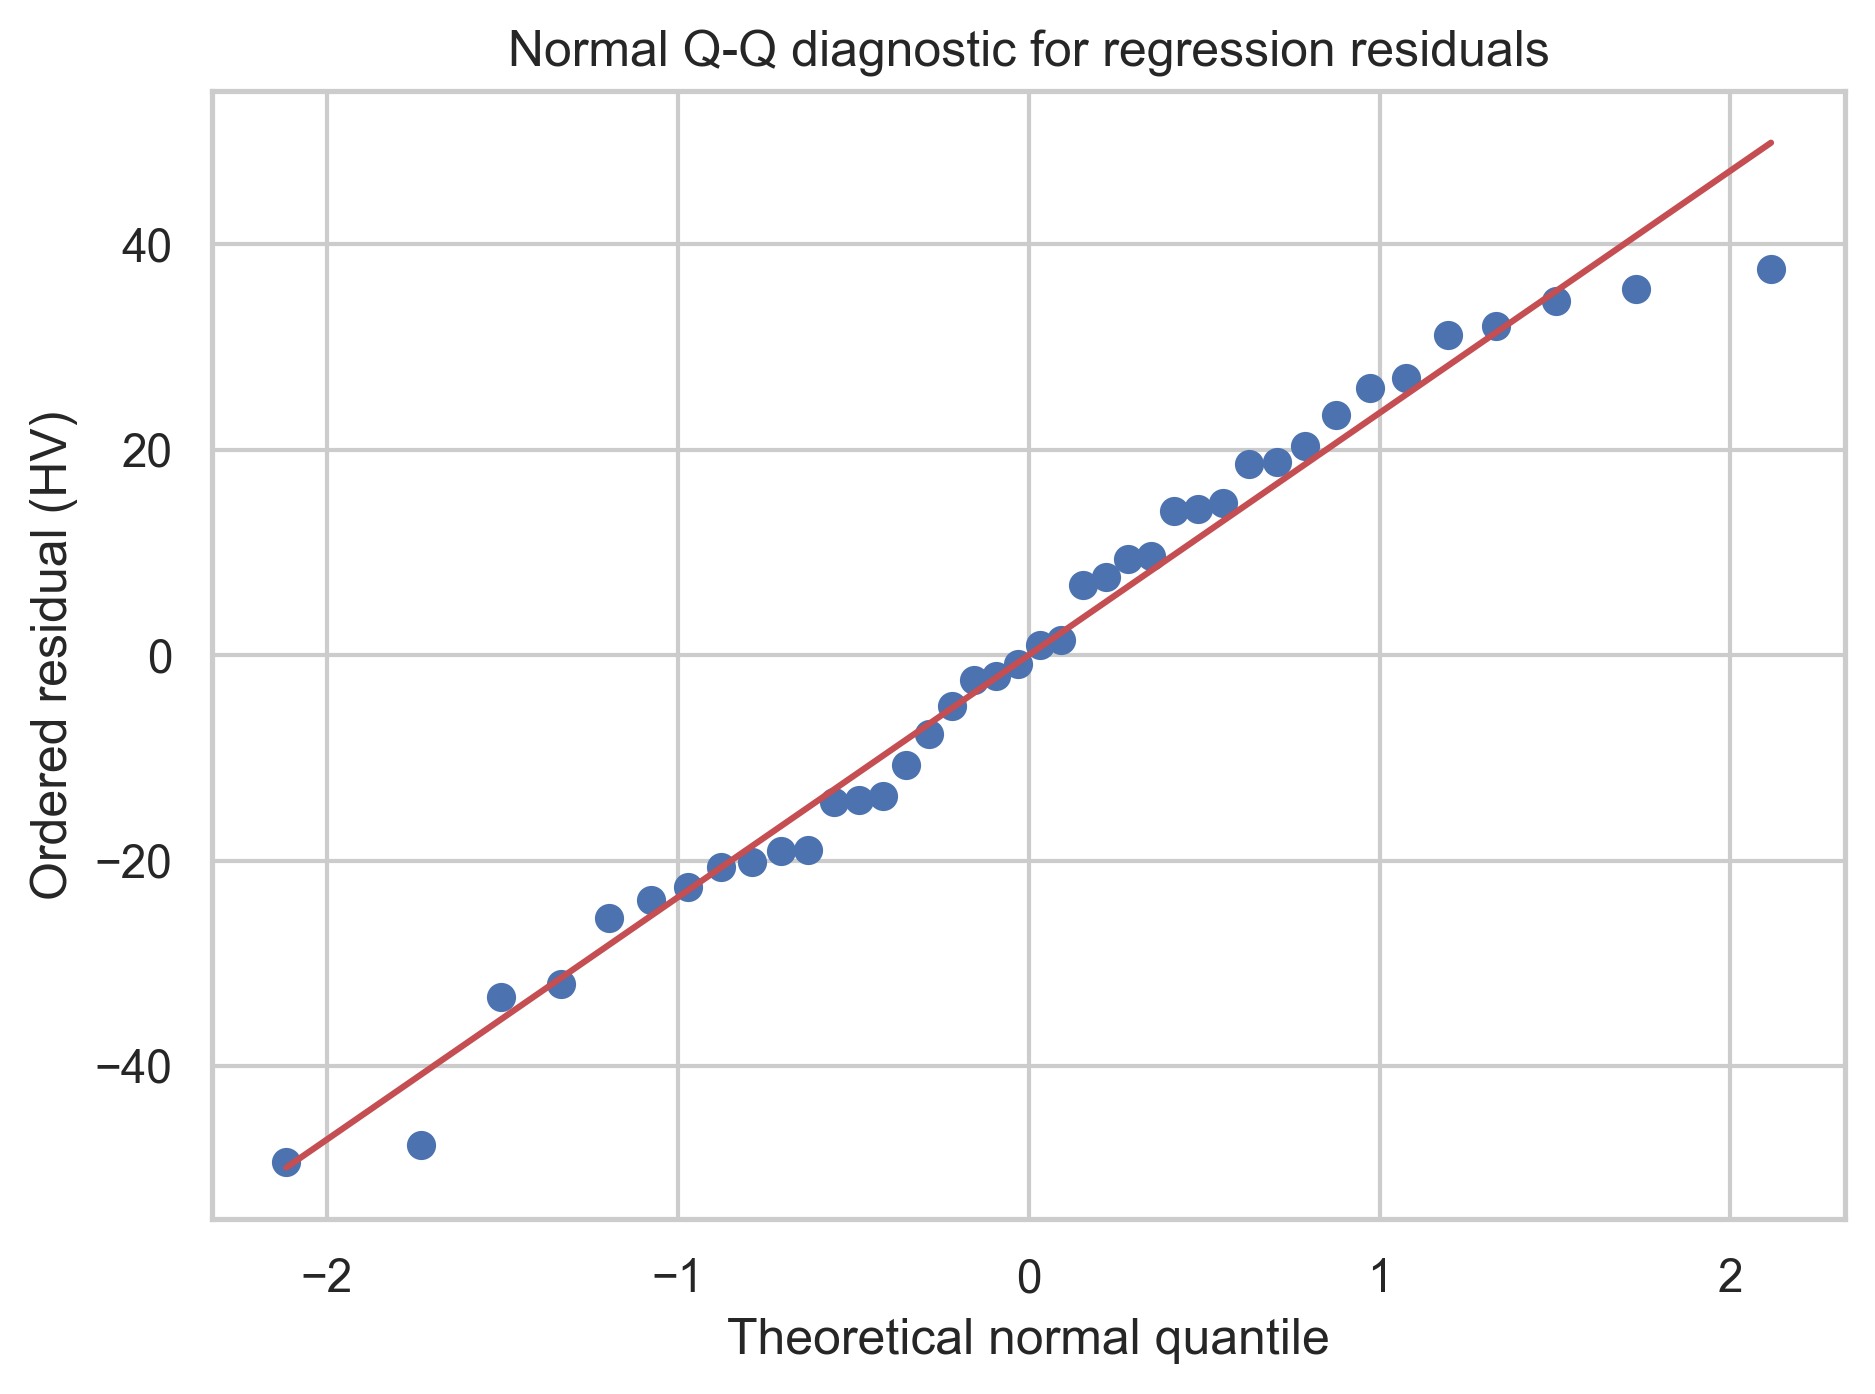

In [16]:
print('Diagnostics:',{k:round(v,5) for k,v in B['diagnostics'].items()})
for name in ['11_residuals_fitted','12_residuals_qq']:
    display(Image(filename=str(FIG/f'{name}.png'),width=720))

### B8. Mean response and new-part prediction at 400 °C

At $x_0=400$, use $\hat y_0=a+bx_0$. A 95% confidence interval estimates the **process mean** at this temperature. A 95% prediction interval adds the variance of one new observation and is wider. For quality control of a single new part, use the prediction interval; for estimating the average process response, use the confidence interval.

,target,point,lower,upper
0,Mean response,401.929,393.778,410.081
1,Single new part,401.929,353.890,449.968


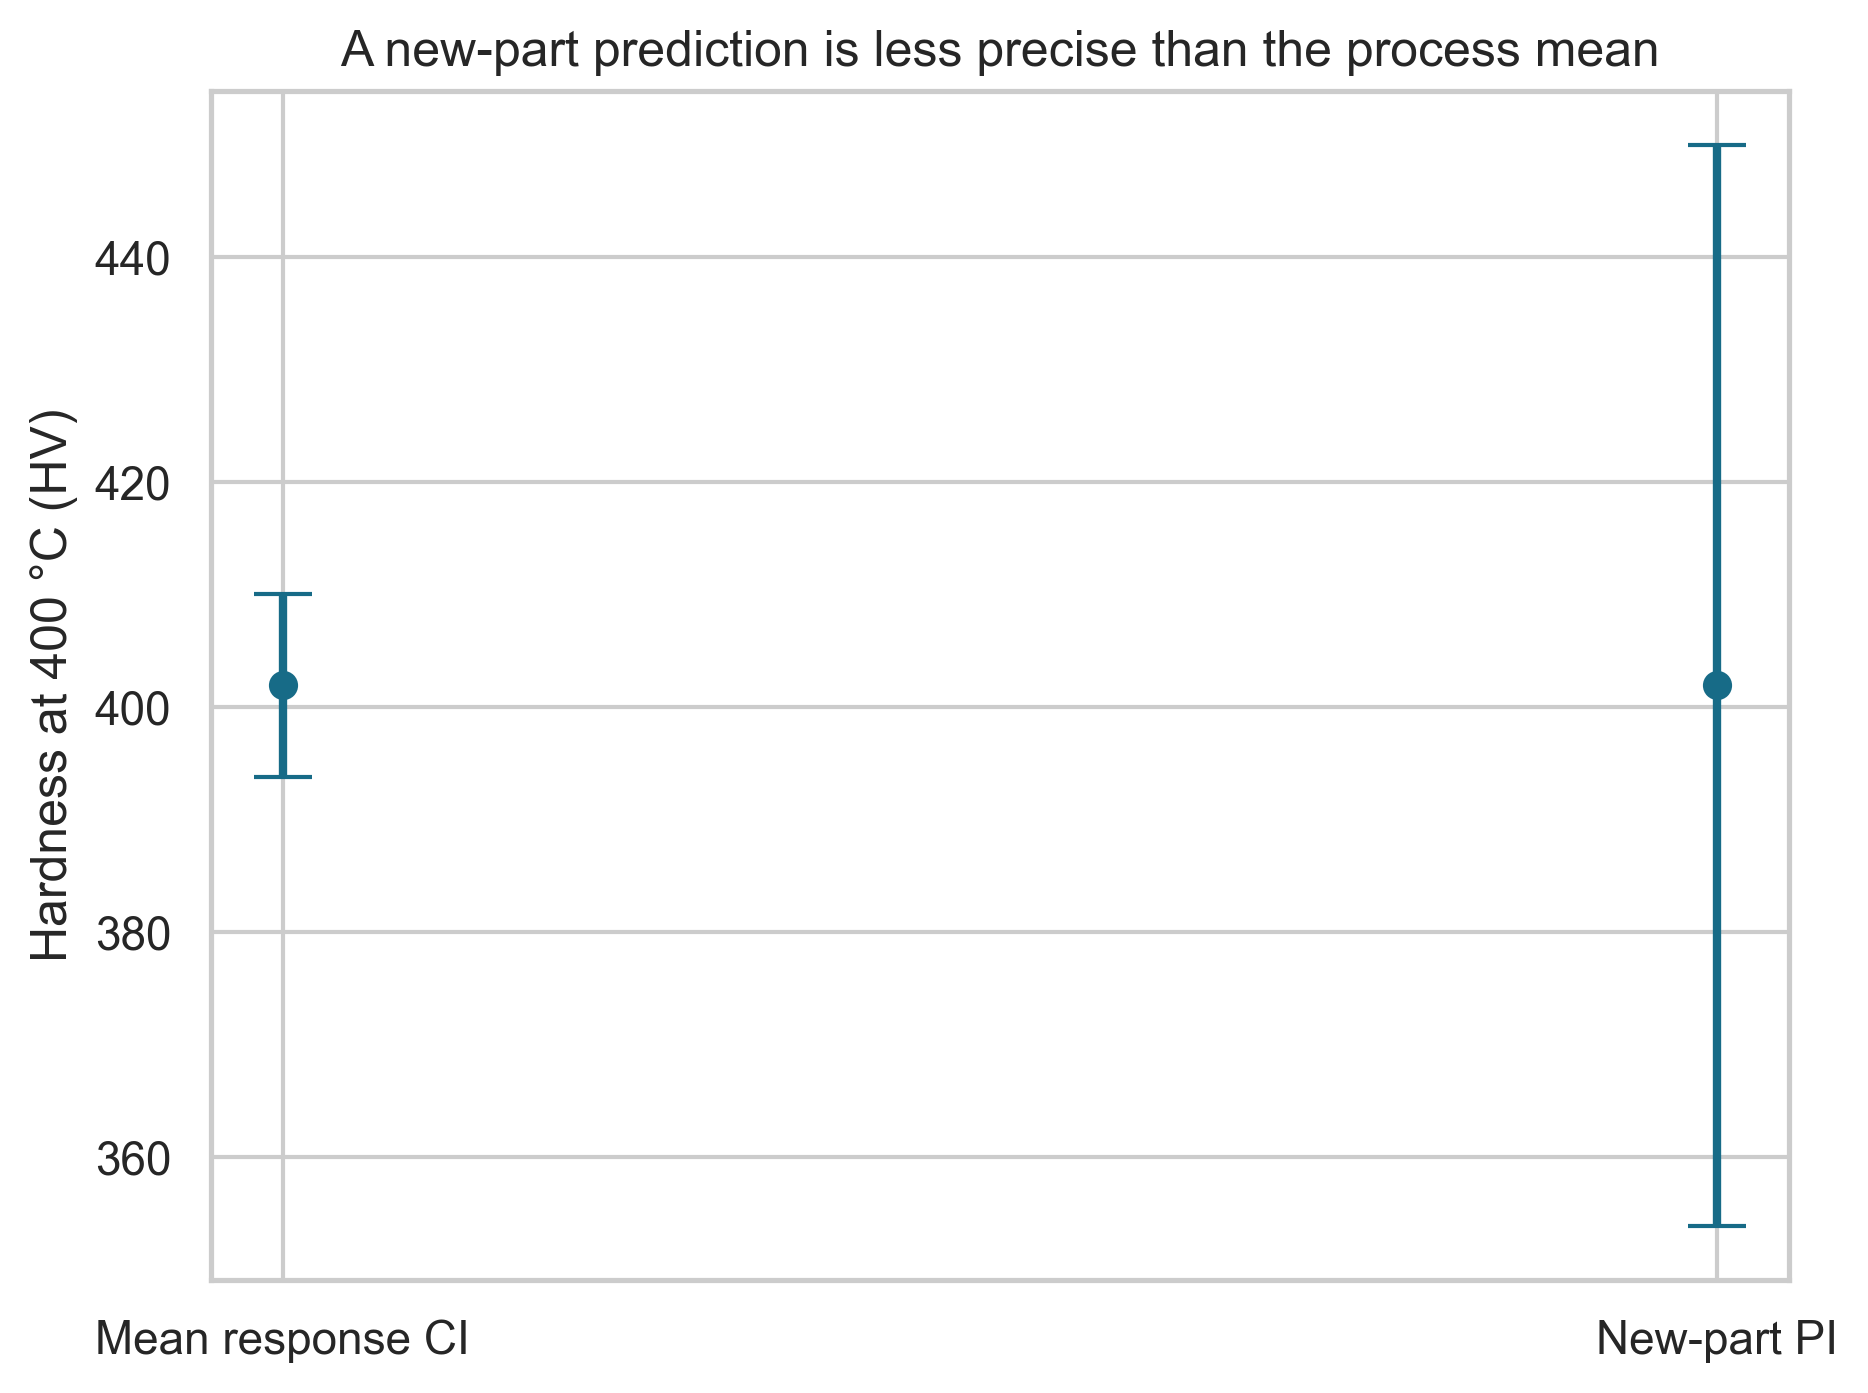

In [17]:
q=B['prediction_400']
display(pd.DataFrame([{'target':'Mean response','point':q['mean_prediction'],
  'lower':q['mean_ci'][0],'upper':q['mean_ci'][1]},
 {'target':'Single new part','point':q['mean_prediction'],
  'lower':q['prediction_interval'][0],'upper':q['prediction_interval'][1]}]).round(3))
display(Image(filename=str(FIG/'13_prediction_intervals.png'),width=700))

## Synthesis and reproducibility

The exponential mean is both the MoM and MLE estimate because the sample mean is the natural moment and sufficient statistic. Gaussian regression coefficient MLEs equal least squares because both optimize the same residual sum of squares. Simulation confirms theoretical bias, variance, consistency, and exact-interval coverage within finite Monte Carlo error; the bootstrap interval shows modest undercoverage in this experiment. A separate regression simulation checks coefficient bias, slope variance, and interval coverage. The two datasets are assignment-provided and realistic-looking, not independently verified observations from an operating factory.

Run `python -m src.run_all` to regenerate results and figures, `python build_notebook.py` to re-execute this notebook, and `python build_report.py` followed by two `pdflatex` passes in `reports/latex` to rebuild the PDF.